# DFlash Optuna investigation: vLLM, H100, concurrency 128

This is an executed, read-only investigation of the six requested W&B studies. The adjacent `dflash_optuna_investigate_data.json` contains the full unsampled histories, configurations, summaries, and file inventories fetched using the existing W&B credentials. Re-execution defaults to that offline snapshot; it launches no servers, benchmarks, or W&B logging runs.

**Findings:** no recorded FAIL trials or failed requests among completed benchmarks; a strong GP/pruning feedback problem; two marginal median-pruning decisions; and several search plateaus that must not be interpreted as a hardware throughput ceiling. Missing acceptance statistics, output-length verification, and server logs prevent ruling out silent runtime problems.

Run links and individual trial parameters/results are displayed below. These runs have no DFlash-off or lower-client-concurrency control.

**Baseline extension:** sections 10–13 compare non-speculative GP run `2f2gjeil`. That run differs in runtime version, request count, pruning, and recorded revision metadata; the comparison is observational, not a controlled DFlash ablation. Richer baseline metrics are included from the matching local JSONL artifact.

**TRT-LLM extension:** sections 14–16 audit `yuvhs01s` against the matching local JSONL/YAML evidence and distinguish the verified 7,623 tokens/s result from the user-reported Nebius 8,000 tokens/s result.

**Earlier Qwen3.5-9B experiment:** sections 17–19 audit the reported DFlash gain at actual concurrency 1, using request tables, result artifacts, client logs and benchmark/launcher source at the recorded commit.

In [1]:
from pathlib import Path
import json
import hashlib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 25)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams.update({"figure.dpi": 115, "axes.grid": True, "grid.alpha": 0.2})
DATA_PATH = next(p for p in [Path("dflash_optuna_investigate_data.json"), Path("docs/dflash_optuna_investigate_data.json")] if p.exists())
REFRESH_FROM_WANDB = False  # Explicit read-only network refresh; needs your W&B login.
snapshot = json.loads(DATA_PATH.read_text())
if REFRESH_FROM_WANDB:
    import wandb
    api = wandb.Api(timeout=60)
    refreshed = []
    for saved in snapshot["runs"]:
        run = api.run(f"{snapshot['project']}/{saved['id']}")
        refreshed.append({"id": run.id, "name": run.name, "state": run.state,
                          "config": dict(run.config), "summary": dict(run.summary),
                          "history": list(run.scan_history(page_size=1000)),
                          "files": [f.name for f in run.files()]})
    snapshot["runs"] = refreshed
    baseline_refreshed = []
    for saved in snapshot.get("baseline_runs", []):
        run = api.run(f"{snapshot['project']}/{saved['id']}")
        baseline_refreshed.append({"id": run.id, "name": run.name, "state": run.state,
                                   "config": dict(run.config), "summary": dict(run.summary),
                                   "history": list(run.scan_history(page_size=1000)),
                                   "files": [f.name for f in run.files()]})
    snapshot["baseline_runs"] = baseline_refreshed
    trt_refreshed = []
    for saved in snapshot.get("trt_runs", []):
        run = api.run(f"{snapshot['project']}/{saved['id']}")
        trt_refreshed.append({"id": run.id, "name": run.name, "state": run.state,
                              "config": dict(run.config), "summary": dict(run.summary),
                              "history": list(run.scan_history(page_size=1000)),
                              "files": [f.name for f in run.files()]})
    snapshot["trt_runs"] = trt_refreshed
    # Keep the original evidence file unchanged. The plots below use this refresh.
runs = snapshot["runs"]
print("Snapshot UTC:", snapshot["exported_at"])
print("Snapshot SHA256:", hashlib.sha256(DATA_PATH.read_bytes()).hexdigest())
print("Source checkout commit:", snapshot["local_source_commit"])
print("Read-only refresh:", REFRESH_FROM_WANDB)

Snapshot UTC: 2026-10-17T16:08:56.263815+00:00
Snapshot SHA256: a8596ec987d2c883eab8104b6dae125e3e404741d82fbce35b16eb48fdae5cd2
Source checkout commit: 5a780ba0ea7b2d6548208684138ca8f485e29e84
Read-only refresh: False


## 1. Experiment identity and completeness

Check the pinned target/draft revisions, workload fingerprint, DFlash server configuration, GPU/runtime, sampler and pruner settings. Recorded verification flags are declarations, not evidence that model outputs were independently validated.

In [2]:
identity = []
records = []
for run in runs:
    c = run["config"]
    env = c["environment"]
    spec = env.get("fixed_server", {}).get("speculative_config", {})
    identity.append({"id": run["id"], "objective": c["target"], "sampler": c["sampler"],
                     "state": run["state"], "rows": len(run["history"]),
                     "target_revision": env.get("model_revision"), "draft_revision": env.get("draft_revision"),
                     "request_hash": env.get("requests_sha256"), "workload_hash": env.get("workload_sha256"),
                     "method": spec.get("method"), "draft_tokens": spec.get("num_speculative_tokens"),
                     "client_concurrency": c["concurrency"], "prompts": c["workload"]["num_prompts"],
                     "gpu": env.get("gpu_type"), "vllm": env.get("framework_version"),
                     "seed": c["sampler_settings"]["seed"], "budget": c["budget_trials"],
                     "pruner": c["pruner_class"], "pruner_settings": json.dumps(c["pruner_settings"], sort_keys=True),
                     "checkpoints": str(c["checkpoint_requests"]), "constrained": c["constrained"]})
    for raw in run["history"]:
        if raw.get("trial/number") is None:
            continue
        record = {**raw, "run_id": run["id"], "sampler": c["sampler"], "target": c["target"],
                  "metric": c["metrics"][0], "number": int(raw["trial/number"]), "state": raw["trial/state"]}
        record["objective"] = raw.get("objective/" + record["metric"])
        records.append(record)
identity = pd.DataFrame(identity)
df = pd.DataFrame(records).sort_values(["run_id", "number"])
complete = df[df.state.eq("COMPLETE")].copy()
pruned = df[df.state.eq("PRUNED")].copy()
for run in runs:
    display(Markdown(f"- [{run['name']}](https://forge.coreweave.com/wandb/{snapshot['project']}/runs/{run['id']})"))
display(identity[["id", "objective", "sampler", "state", "rows", "method", "draft_tokens", "client_concurrency", "prompts", "vllm", "seed", "budget"]])
display(identity[["id", "pruner_settings", "checkpoints", "constrained"]])
for field in ["target_revision", "draft_revision", "request_hash", "workload_hash", "gpu"]:
    print(field, identity[field].unique().tolist())
assert len(df) == 120
assert all(len(r["history"]) == 20 for r in runs)
assert not df.duplicated(["run_id", "number"]).any()
assert all(set(g.number) == set(range(20)) for _, g in df.groupby("run_id"))
assert identity[["target_revision", "draft_revision", "request_hash", "workload_hash"]].nunique().eq(1).all()
assert identity.method.eq("dflash").all()

- [B-vllm-c128-throughput-gp-s11-r1-pruner-median](https://forge.coreweave.com/wandb/maorblumberg-tel-aviv-university/inference-optimization/runs/zbyjlkdk)

- [B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median](https://forge.coreweave.com/wandb/maorblumberg-tel-aviv-university/inference-optimization/runs/cvzosd1r)

- [B-vllm-c128-throughput-tpe-s11-r1-pruner-median](https://forge.coreweave.com/wandb/maorblumberg-tel-aviv-university/inference-optimization/runs/qyu0g3ke)

- [B-vllm-c128-e2e-gp-s11-r1-pruner-median](https://forge.coreweave.com/wandb/maorblumberg-tel-aviv-university/inference-optimization/runs/8gp1fym7)

- [B-vllm-c128-e2e-tpe_multivariate-s11-r1-pruner-median](https://forge.coreweave.com/wandb/maorblumberg-tel-aviv-university/inference-optimization/runs/s0k095o0)

- [B-vllm-c128-e2e-tpe-s11-r1-pruner-median](https://forge.coreweave.com/wandb/maorblumberg-tel-aviv-university/inference-optimization/runs/g84ks3ri)

,id,objective,sampler,state,rows,method,draft_tokens,client_concurrency,prompts,vllm,seed,budget
0,zbyjlkdk,throughput,gp,finished,20,dflash,15,128,1000,0.31.0,11,20
1,cvzosd1r,throughput,tpe_multivariate,finished,20,dflash,15,128,1000,0.31.0,11,20
2,qyu0g3ke,throughput,tpe,finished,20,dflash,15,128,1000,0.31.0,11,20
3,8gp1fym7,e2e,gp,finished,20,dflash,15,128,1000,0.31.0,11,20
4,s0k095o0,e2e,tpe_multivariate,finished,20,dflash,15,128,1000,0.31.0,11,20
5,g84ks3ri,e2e,tpe,finished,20,dflash,15,128,1000,0.31.0,11,20


,id,pruner_settings,checkpoints,constrained
0,zbyjlkdk,"{""n_min_trials"": 3, ""n_startup_trials"": 10, ""n_warmup_steps"": 400}","[400, 500, 1000]",False
1,cvzosd1r,"{""n_min_trials"": 3, ""n_startup_trials"": 10, ""n_warmup_steps"": 400}","[400, 500, 1000]",False
2,qyu0g3ke,"{""n_min_trials"": 3, ""n_startup_trials"": 10, ""n_warmup_steps"": 400}","[400, 500, 1000]",False
3,8gp1fym7,"{""n_min_trials"": 3, ""n_startup_trials"": 10, ""n_warmup_steps"": 400}","[400, 500, 1000]",False
4,s0k095o0,"{""n_min_trials"": 3, ""n_startup_trials"": 10, ""n_warmup_steps"": 400}","[400, 500, 1000]",False
5,g84ks3ri,"{""n_min_trials"": 3, ""n_startup_trials"": 10, ""n_warmup_steps"": 400}","[400, 500, 1000]",False


target_revision ['851bf6e806efd8d0a36b00ddf55e13ccb7b8cd0a']
draft_revision ['9a1996ccf887b79ab3af4fcbf8c1d1f4b5658bcf']
request_hash ['0917cefa5e6787dd7cbb8b88d312b1f07b8cfe5b763a3a0b6dc657c688b46c23']
workload_hash ['77bcc433ccffcaad058729fae367fca7a405ed50aeea7cbafcdb8536dd604367']
gpu ['NVIDIA H100 80GB HBM3']


## 2. Trial outcomes, winners and silent-failure checks

Full benchmark measurements are kept separate from partial/pruned checkpoints. A PRUNED trial's `requests/total_requests=400` describes the observed prefix; `requests/planned_requests=1000` describes the intended workload. The cancelled remainder is not counted as successful requests or as a server failure.

W&B's run summary retains the last logged value of each key. If a final trial is pruned, `trial/state` and parameters can describe that trial while `benchmark/*` and `objective/*` still describe an earlier COMPLETE trial. Do not combine those summary fields into one apparent benchmark result.

In [3]:
summaries = []
winners = []
for run in runs:
    group = df[df.run_id.eq(run["id"])]
    valid = group[group.state.eq("COMPLETE")]
    best = valid.loc[valid.objective.idxmax() if run["config"]["target"] == "throughput" else valid.objective.idxmin()]
    counts = group.state.value_counts()
    summaries.append({"run": run["id"], "target": best.target, "sampler": best.sampler,
                      "complete": counts.get("COMPLETE", 0), "pruned": counts.get("PRUNED", 0), "fail": counts.get("FAIL", 0),
                      "unique_configs": group["trial/config_id"].nunique(), "best_trial": int(best.number), "best_value": best.objective,
                      "tail_without_new_best": int(group.number.max() - best.number),
                      "allocated_gpu_s": group["trial/gpu_seconds"].sum(),
                      "pruned_gpu_s": group.loc[group.state.eq("PRUNED"), "trial/gpu_seconds"].sum(),
                      "feasible_complete": int(valid["trial/slo_feasible"].eq(True).sum())})
    winners.append({"run": run["id"], "target": best.target, "sampler": best.sampler, "trial": int(best.number),
                    "throughput_tok_s": best.get("benchmark/output_throughput"),
                    "p95_e2e_ms": best.get("benchmark/p95_e2e_latency_ms"), "p95_ttft_ms": best.get("benchmark/p95_ttft_ms"),
                    "parameters": {k.removeprefix("parameters/"): v for k, v in best.items()
                                   if k.startswith("parameters/") and v is not None and not (isinstance(v, float) and np.isnan(v))}})
summary = pd.DataFrame(summaries)
display(summary)
display(pd.DataFrame(winners))
checks = {
    "FAIL trials": int(df.state.eq("FAIL").sum()),
    "COMPLETE trials with nonzero failed requests": int(complete["benchmark/failed"].fillna(-1).ne(0).sum()),
    "COMPLETE trials not completing 1000 requests": int(complete["benchmark/completed"].fillna(-1).ne(1000).sum()),
    "COMPLETE trials with changed total request count": int(complete["benchmark/total_requests"].fillna(-1).ne(1000).sum()),
    "COMPLETE trials with missing/nonpositive objectives": int((~np.isfinite(complete.objective) | complete.objective.le(0)).sum()),
    "Nonempty failure reasons": sum(bool(r.get("trial/failure_reason")) for run in runs for r in run["history"]),
    "PRUNED trials without 400 completed requests": int(pruned["requests/completed"].fillna(-1).ne(400).sum()),
    "PRUNED trials with failed observed requests": int(pruned["requests/failed"].fillna(-1).ne(0).sum()),
}
display(pd.Series(checks, name="count").to_frame())
assert not any(checks.values())
assert len(complete) == 97 and len(pruned) == 23
assert complete.apply(lambda r: np.isclose(r.objective, r["benchmark/" + r.metric]), axis=1).all()
assert all(not r["summary"].get("interrupted", False) for r in runs)
stale = []
for run in runs:
    rows = sorted(run["history"], key=lambda r: r["trial/number"])
    final = rows[-1]
    latest_complete = next(r for r in reversed(rows) if r["trial/state"] == "COMPLETE")
    stale.append({"run": run["id"], "last_trial": final["trial/number"], "last_state": final["trial/state"],
                  "last_complete_trial": latest_complete["trial/number"],
                  "summary_mixes_trial_and_old_benchmark": final["trial/state"] != "COMPLETE" and "benchmark/output_throughput" in run["summary"]})
display(pd.DataFrame(stale))

,run,target,sampler,complete,pruned,fail,unique_configs,best_trial,best_value,tail_without_new_best,allocated_gpu_s,pruned_gpu_s,feasible_complete
0,zbyjlkdk,throughput,gp,13,7,0,19,6,"5,613.565",13,"2,441.728",962.254,0
1,cvzosd1r,throughput,tpe_multivariate,17,3,0,20,18,"5,710.270",1,"2,426.617",346.641,0
2,qyu0g3ke,throughput,tpe,19,1,0,20,15,"5,571.983",4,"2,513.054",82.804,0
3,8gp1fym7,e2e,gp,14,6,0,16,11,"4,124.129",8,"2,310.167",683.227,0
4,s0k095o0,e2e,tpe_multivariate,15,5,0,20,11,"4,091.350",8,"2,441.023",673.123,0
5,g84ks3ri,e2e,tpe,19,1,0,20,16,"4,052.711",3,"3,359.061",129.468,0


,run,target,sampler,trial,throughput_tok_s,p95_e2e_ms,p95_ttft_ms,parameters
0,zbyjlkdk,throughput,gp,6,"5,613.565","4,411.515","1,734.331","{'kv_cache_dtype': 'fp8', 'max_num_seqs': 88, 'enable_prefix_caching': True, 'max_num_batched_tokens': 209..."
1,cvzosd1r,throughput,tpe_multivariate,18,"5,710.270","4,226.784","1,744.559","{'kv_cache_dtype': 'auto', 'max_num_seqs': 96, 'enable_prefix_caching': False, 'max_num_batched_tokens': 1..."
2,qyu0g3ke,throughput,tpe,15,"5,571.983","4,362.701","1,827.654","{'kv_cache_dtype': 'fp8', 'max_num_seqs': 104, 'enable_prefix_caching': False, 'max_num_batched_tokens': 1..."
3,8gp1fym7,e2e,gp,11,"5,492.745","4,124.129","2,024.806","{'kv_cache_dtype': 'auto', 'max_num_seqs': 88, 'enable_prefix_caching': False, 'max_num_batched_tokens': 2..."
4,s0k095o0,e2e,tpe_multivariate,11,"5,511.514","4,091.350","2,103.788","{'kv_cache_dtype': 'auto', 'max_num_seqs': 96, 'enable_prefix_caching': False, 'max_num_batched_tokens': 1..."
5,g84ks3ri,e2e,tpe,16,"5,493.744","4,052.711","2,054.196","{'kv_cache_dtype': 'auto', 'max_num_seqs': 72, 'enable_prefix_caching': False, 'max_num_batched_tokens': 5..."


,count
FAIL trials,0
COMPLETE trials with nonzero failed requests,0
COMPLETE trials not completing 1000 requests,0
COMPLETE trials with changed total request count,0
COMPLETE trials with missing/nonpositive objectives,0
Nonempty failure reasons,0
PRUNED trials without 400 completed requests,0
PRUNED trials with failed observed requests,0


,run,last_trial,last_state,last_complete_trial,summary_mixes_trial_and_old_benchmark
0,zbyjlkdk,19,PRUNED,13,True
1,cvzosd1r,19,COMPLETE,19,False
2,qyu0g3ke,19,COMPLETE,19,False
3,8gp1fym7,19,PRUNED,13,True
4,s0k095o0,19,COMPLETE,19,False
5,g84ks3ri,19,COMPLETE,19,False


**Interpretation:** all 97 COMPLETE trials report 1000 completed requests and zero failed requests. All 23 PRUNED trials report 400 observed successes and zero observed failures. This rules out *recorded* benchmark/request failures; it does not validate output correctness, draft-token acceptance, token accounting, or native runtime behavior. All runs are unconstrained, and every completed trial is marked SLO-infeasible; optimization success therefore does not mean the TTFT/E2E SLOs were met.

## 3. Convergence and plateaus

Dots are full objectives; crosses are the last reported partial objectives. Crosses cannot be compared as completed benchmarks. Lines show the incumbent based only on COMPLETE trials. A flat incumbent is a search plateau, not proof that individual measurements became constant.

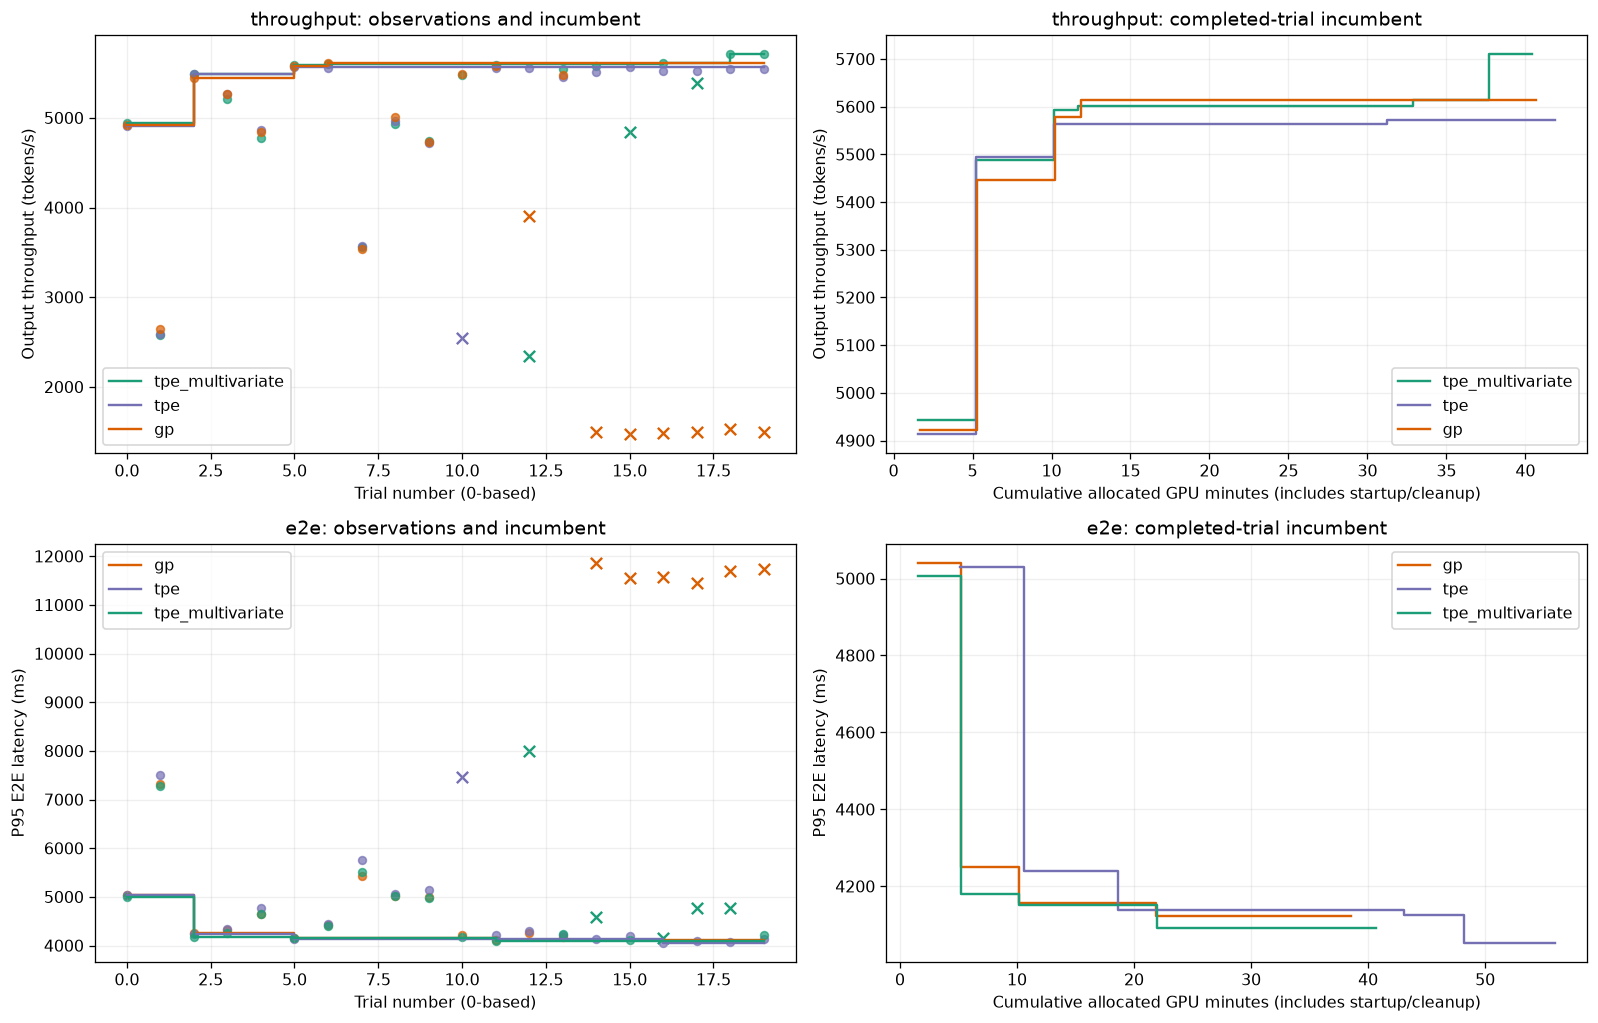

In [4]:
colors = {"gp": "#d95f02", "tpe_multivariate": "#1b9e77", "tpe": "#7570b3"}
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for row, target in enumerate(["throughput", "e2e"]):
    for rid, g in df[df.target.eq(target)].groupby("run_id"):
        g = g.sort_values("number")
        sampler = g.sampler.iloc[0]
        good = g[g.state.eq("COMPLETE")]
        bad = g[g.state.eq("PRUNED")]
        vals = g.objective.where(g.state.eq("COMPLETE"))
        incumbent = (vals.cummax() if target == "throughput" else vals.cummin()).ffill()
        partial = bad["trial/intermediate_values.400"]
        axes[row, 0].scatter(good.number, good.objective, color=colors[sampler], s=24, alpha=0.7)
        axes[row, 0].scatter(bad.number, partial, color=colors[sampler], marker="x", s=50)
        axes[row, 0].step(g.number, incumbent, where="post", color=colors[sampler], label=sampler)
        cost = g["trial/gpu_seconds"].cumsum()
        axes[row, 1].step(cost / 60, incumbent, where="post", color=colors[sampler], label=sampler)
    label = "Output throughput (tokens/s)" if target == "throughput" else "P95 E2E latency (ms)"
    axes[row, 0].set(xlabel="Trial number (0-based)", ylabel=label, title=f"{target}: observations and incumbent")
    axes[row, 1].set(xlabel="Cumulative allocated GPU minutes (includes startup/cleanup)", ylabel=label, title=f"{target}: completed-trial incumbent")
    for ax in axes[row]: ax.legend()
fig.tight_layout()
plt.show()

Throughput TPE stays near 5.5–5.6k tokens/s after the startup phase, while multivariate TPE reaches 5,710 tokens/s at trial 18. GP's best throughput remains its startup trial 6. GP E2E's best trial is 11; trials 14–19 do not add a complete observation. These are 20-trial, single-seed quick-demo studies with 10 startup trials, so they cannot establish sampler superiority or a hardware ceiling.

## 4. Exact MedianPruner replay and pruning margins

Replay the actual Optuna MedianPruner against each preceding COMPLETE trial, using only recorded checkpoints. No final objective is inserted into an intermediate trajectory. Terminal checkpoint 1000 is not eligible for pruning in this integration. The median comparator uses the same step; the current trial is assessed using its best intermediate value so far.

A matching decision verifies implementation consistency, not that pruning was statistically well justified.

Replay Optuna version: 4.9.0 ; run version: 4.9.0
Decisions checked: 217 ; mismatches: 0


/home/maorb/.venvs/bento_extend/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,run,target,sampler,trial,step,previous_complete,checkpoint_value,median,worse_than_median_pct
24,zbyjlkdk,throughput,gp,12,400,12,"3,909.213","5,092.820",23.241
27,zbyjlkdk,throughput,gp,14,400,13,"1,492.017","5,250.353",71.583
28,zbyjlkdk,throughput,gp,15,400,13,"1,473.776","5,250.353",71.930
29,zbyjlkdk,throughput,gp,16,400,13,"1,489.211","5,250.353",71.636
30,zbyjlkdk,throughput,gp,17,400,13,"1,499.006","5,250.353",71.449
31,zbyjlkdk,throughput,gp,18,400,13,"1,528.421","5,250.353",70.889
32,zbyjlkdk,throughput,gp,19,400,13,"1,493.377","5,250.353",71.557
57,cvzosd1r,throughput,tpe_multivariate,12,400,12,"2,345.372","5,006.761",53.156
62,cvzosd1r,throughput,tpe_multivariate,15,400,14,"4,837.082","5,251.226",7.887
65,cvzosd1r,throughput,tpe_multivariate,17,400,15,"5,392.701","5,397.941",0.097


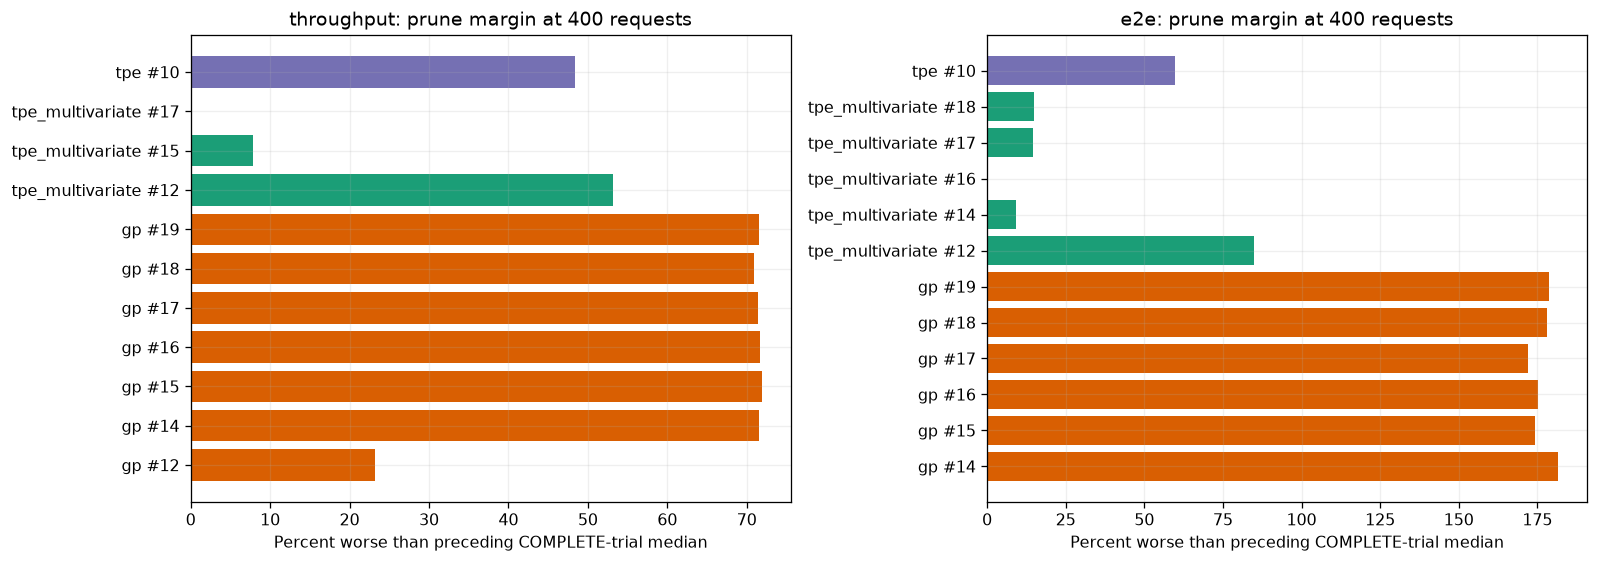

In [5]:
import optuna
from optuna.trial import TrialState
optuna.logging.set_verbosity(optuna.logging.WARNING)
assert optuna.__version__ == runs[0]["config"]["environment"]["optuna"], "Replay requires the run's Optuna version."
replay = []
for run in runs:
    cfg = run["config"]
    pruner = optuna.pruners.MedianPruner(**cfg["pruner_settings"])
    study = optuna.create_study(direction=cfg["directions"][0].lower(), pruner=pruner)
    previous_complete = []
    for raw in sorted(run["history"], key=lambda r: r["trial/number"]):
        intermediates = {int(k.rsplit(".", 1)[1]): float(v) for k, v in raw.items()
                         if k.startswith("trial/intermediate_values.") and v is not None}
        observed_prefix = {}
        eligible_steps = [s for s in sorted(intermediates) if s < cfg["checkpoint_requests"][-1]]
        for step in eligible_steps:
            observed_prefix[step] = intermediates[step]
            frozen = optuna.trial.create_trial(state=TrialState.RUNNING, intermediate_values=observed_prefix)
            predicted = pruner.prune(study, frozen)
            actual = raw["trial/state"] == "PRUNED" and step == max(intermediates)
            peers = [p[step] for p in previous_complete if step in p]
            threshold = float(np.median(peers)) if peers else np.nan
            minimizing = cfg["directions"][0] == "MINIMIZE"
            best_prefix = min(observed_prefix.values()) if minimizing else max(observed_prefix.values())
            worse_pct = 100 * ((best_prefix - threshold) if minimizing else (threshold - best_prefix)) / abs(threshold)
            replay.append({"run": run["id"], "target": cfg["target"], "sampler": cfg["sampler"],
                           "trial": raw["trial/number"], "step": step, "previous_complete": len(previous_complete),
                           "checkpoint_value": intermediates[step], "median": threshold,
                           "worse_than_median_pct": worse_pct, "predicted_prune": bool(predicted),
                           "actual_prune": actual, "decision_matches": bool(predicted) == actual})
        state = TrialState[raw["trial/state"]]
        kwargs = {"state": state, "intermediate_values": intermediates}
        if state == TrialState.COMPLETE:
            kwargs["value"] = raw["objective/" + cfg["metrics"][0]]
            previous_complete.append(intermediates)
        study.add_trial(optuna.trial.create_trial(**kwargs))
replay = pd.DataFrame(replay)
print("Replay Optuna version:", optuna.__version__, "; run version:", runs[0]["config"]["environment"]["optuna"])
print("Decisions checked:", len(replay), "; mismatches:", int((~replay.decision_matches).sum()))
assert replay.decision_matches.all()
assert replay[replay.actual_prune].step.eq(400).all()
display(replay[replay.actual_prune][["run", "target", "sampler", "trial", "step", "previous_complete", "checkpoint_value", "median", "worse_than_median_pct"]])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, target in zip(axes, ["throughput", "e2e"]):
    subset = replay[replay.actual_prune & replay.target.eq(target)]
    ax.barh([f"{r.sampler} #{r.trial}" for r in subset.itertuples()], subset.worse_than_median_pct,
            color=[colors[s] for s in subset.sampler])
    ax.set(xlabel="Percent worse than preceding COMPLETE-trial median", title=f"{target}: prune margin at 400 requests")
fig.tight_layout()
plt.show()

**Marginal decisions:** throughput multivariate TPE trial 17 was pruned at 5,392.70 versus a median of 5,397.94 tokens/s (only **0.097% worse**). E2E multivariate TPE trial 16 was pruned at 4,165.04 versus 4,159.09 ms (**0.143% worse**). Neither violates the configured rule, which has no practical-effect/noise margin. Their final results are unknown; they should not be called failures or assumed to have remained worse. All pruning occurred at 400, so no pruned candidate survived to the 500 checkpoint.

## 5. GP feedback, duplicate configurations and execution cost

The GP tails repeatedly test very small server batch capacities (`max_num_seqs=8`) under client concurrency 128. They are measured as poor and then pruned, but the GP does not learn from the pruned observations. In Optuna 4.9.0, `GPSampler.sample_relative` selects completed observations for fitting; PRUNED trials are excluded. The current repository GP failure policy adds only FAIL trials to the blocklist, so these PRUNED configurations are not blocked.

This is a strong explanation for the observed loop; it does not require a DFlash runtime failure. Exact acquisition behavior cannot be reconstructed without the Optuna database and sampler state. Sources: [versioned GP source](https://github.com/optuna/optuna/blob/v4.9.0/optuna/samplers/_gp/sampler.py), [MedianPruner implementation](https://github.com/optuna/optuna/blob/v4.9.0/optuna/pruners/_percentile.py), local `src/llm_optimizer/experiment/gp_policy.py` and the prune notebook objective/callback.

,run,sampler,target,config_id,trials,states,duplicate_executions,extra_allocated_gpu_s
0,8gp1fym7,gp,e2e,6fda77362fca471b,"[15, 16, 17]","[PRUNED, PRUNED, PRUNED]",2,192.985
1,8gp1fym7,gp,e2e,c9486a6aae3dc957,"[14, 18, 19]","[PRUNED, PRUNED, PRUNED]",2,194.863
2,zbyjlkdk,gp,throughput,2bcf6c09a19c60b0,"[17, 18]","[PRUNED, PRUNED]",1,96.330


,run_id,target,number,state,trial/config_id,parameters/max_num_seqs,parameters/max_num_batched_tokens,parameters/graph_capture_profile,trial/intermediate_values.400,trial/gpu_seconds
74,8gp1fym7,e2e,14,PRUNED,c9486a6aae3dc957,8,30208,dense,"11,861.574",148.013
75,8gp1fym7,e2e,15,PRUNED,6fda77362fca471b,8,30208,powers,"11,546.509",147.366
76,8gp1fym7,e2e,16,PRUNED,6fda77362fca471b,8,30208,powers,"11,582.442",96.688
77,8gp1fym7,e2e,17,PRUNED,6fda77362fca471b,8,30208,powers,"11,448.612",96.297
78,8gp1fym7,e2e,18,PRUNED,c9486a6aae3dc957,8,30208,dense,"11,705.097",97.020
79,8gp1fym7,e2e,19,PRUNED,c9486a6aae3dc957,8,30208,dense,"11,731.615",97.843
14,zbyjlkdk,throughput,14,PRUNED,263bbbf6b50d4344,8,14848,powers,"1,492.017",147.749
15,zbyjlkdk,throughput,15,PRUNED,03b6f90abf2f2cf1,8,14848,dense,"1,473.776",148.270
16,zbyjlkdk,throughput,16,PRUNED,9a06b519cbf11411,8,27904,dense,"1,489.211",147.759
17,zbyjlkdk,throughput,17,PRUNED,2bcf6c09a19c60b0,8,27904,powers,"1,499.006",147.668


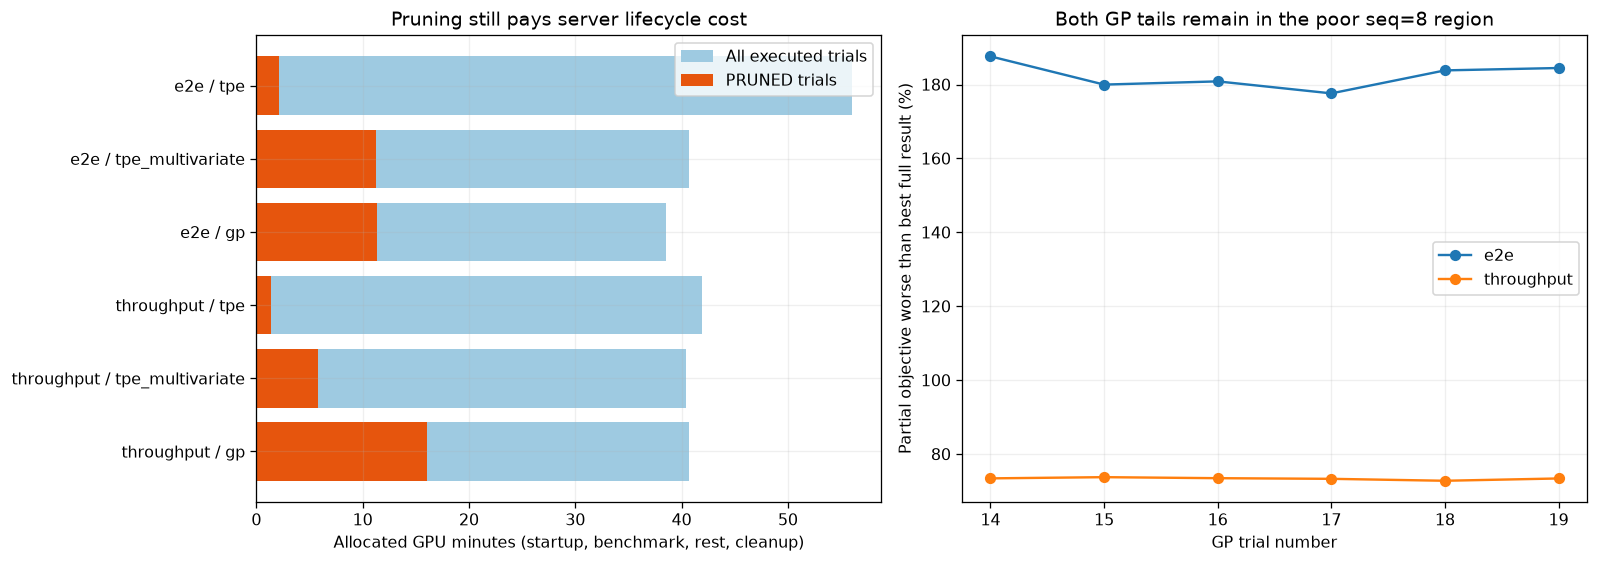

In [6]:
# Verify logged config IDs against the resolved native settings, including fixed DFlash.
run_by_id = {run["id"]: run for run in runs}
def resolved_signature(row):
    settings = dict(run_by_id[row["run_id"]]["config"]["environment"].get("fixed_server", {}))
    for key, value in row.items():
        if key.startswith("trial/config.") and value is not None and not (isinstance(value, float) and np.isnan(value)):
            settings[key.removeprefix("trial/config.")] = value
    return json.dumps(settings, sort_keys=True)
df["resolved_signature"] = df.apply(resolved_signature, axis=1)
assert df.groupby(["run_id", "trial/config_id"]).resolved_signature.nunique().eq(1).all()
duplicates = []
for (rid, cid), g in df.groupby(["run_id", "trial/config_id"]):
    if len(g) > 1:
        first = g.sort_values("number").iloc[0]
        duplicates.append({"run": rid, "sampler": first.sampler, "target": first.target, "config_id": cid,
                           "trials": list(g.number.astype(int)), "states": list(g.state),
                           "duplicate_executions": len(g) - 1,
                           "extra_allocated_gpu_s": g.sort_values("number")["trial/gpu_seconds"].iloc[1:].sum()})
duplicate_table = pd.DataFrame(duplicates)
display(duplicate_table)
gp_tail = df[df.sampler.eq("gp") & df.number.ge(14)]
display(gp_tail[["run_id", "target", "number", "state", "trial/config_id", "parameters/max_num_seqs",
                 "parameters/max_num_batched_tokens", "parameters/graph_capture_profile", "trial/intermediate_values.400", "trial/gpu_seconds"]])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
labels = summary.target + " / " + summary.sampler
axes[0].barh(labels, summary.allocated_gpu_s / 60, label="All executed trials", color="#9ecae1")
axes[0].barh(labels, summary.pruned_gpu_s / 60, label="PRUNED trials", color="#e6550d")
axes[0].set(xlabel="Allocated GPU minutes (startup, benchmark, rest, cleanup)", title="Pruning still pays server lifecycle cost")
axes[0].legend()
for target, g in gp_tail.groupby("target"):
    best_full = summary[(summary.sampler == "gp") & (summary.target == target)].best_value.iloc[0]
    partial = g["trial/intermediate_values.400"]
    loss_pct = 100 * (1 - partial / best_full) if target == "throughput" else 100 * (partial / best_full - 1)
    axes[1].plot(g.number, loss_pct, marker="o", label=target)
axes[1].set(xlabel="GP trial number", ylabel="Partial objective worse than best full result (%)", title="Both GP tails remain in the poor seq=8 region")
axes[1].legend()
fig.tight_layout()
plt.show()

The GP E2E tail executes only **two distinct configurations six times** (four redundant executions). GP throughput repeats trials 17 and 18 exactly. Failed-config protection is functioning within its stated scope; it was never intended to reject previously pruned configurations. **Do not relabel PRUNED trials as FAIL or assign penalty objectives to hide this.** A follow-up can compare GP without pruning, complete selected rejected configurations, or separately design bounded treatment of known pruned duplicates while preserving Optuna semantics.

`trial/gpu_seconds` is an allocated-wall-time proxy. It includes process startup/compilation and rest; it is not benchmark generation duration or sampled GPU utilization. Therefore pruning 60% of requests does not imply a 60% wall-cost saving.

## 6. Repeated startup settings, measurement variation and checkpoint bias

All six studies share seed 11 and the first ten effective configurations. These give repeated configuration measurements across studies, not six independent optimizer searches. Full-metric range includes temporal variation and possible warmup/cache effects; it is not a confidence interval. Only compare identical config IDs after verifying the shared workload/environment above.

,startup_trial,config_id,repeats,max_num_seqs,max_num_batched_tokens,throughput_range_pct_of_median,throughput_cv_pct,p95_e2e_range_pct_of_median,p95_e2e_cv_pct
1,0,1b953a706da956d1,6,72,16896,2.737,0.951,1.443,0.507
8,1,bec5e096ea115181,6,88,1536,3.641,1.521,3.505,1.542
0,2,0cc5f07091afce03,6,128,32512,2.361,0.844,2.070,0.798
2,3,1f0e64865ba706ab,6,56,24320,4.183,1.701,4.169,1.708
6,4,67942c3b1f0c8828,6,48,20480,3.928,1.511,2.732,1.251
5,5,665e7d3262e8f278,6,104,11520,0.928,0.341,0.719,0.244
9,6,f90b9e87c3a1a33a,6,88,20992,1.601,0.622,0.995,0.367
3,7,317c08cf619750e8,6,24,18688,6.675,2.377,6.393,2.404
7,8,bc1b871fccc580c9,6,120,31488,2.315,0.919,1.558,0.534
4,9,4935d1a49ad8bd76,6,120,12288,4.460,1.715,3.728,1.360


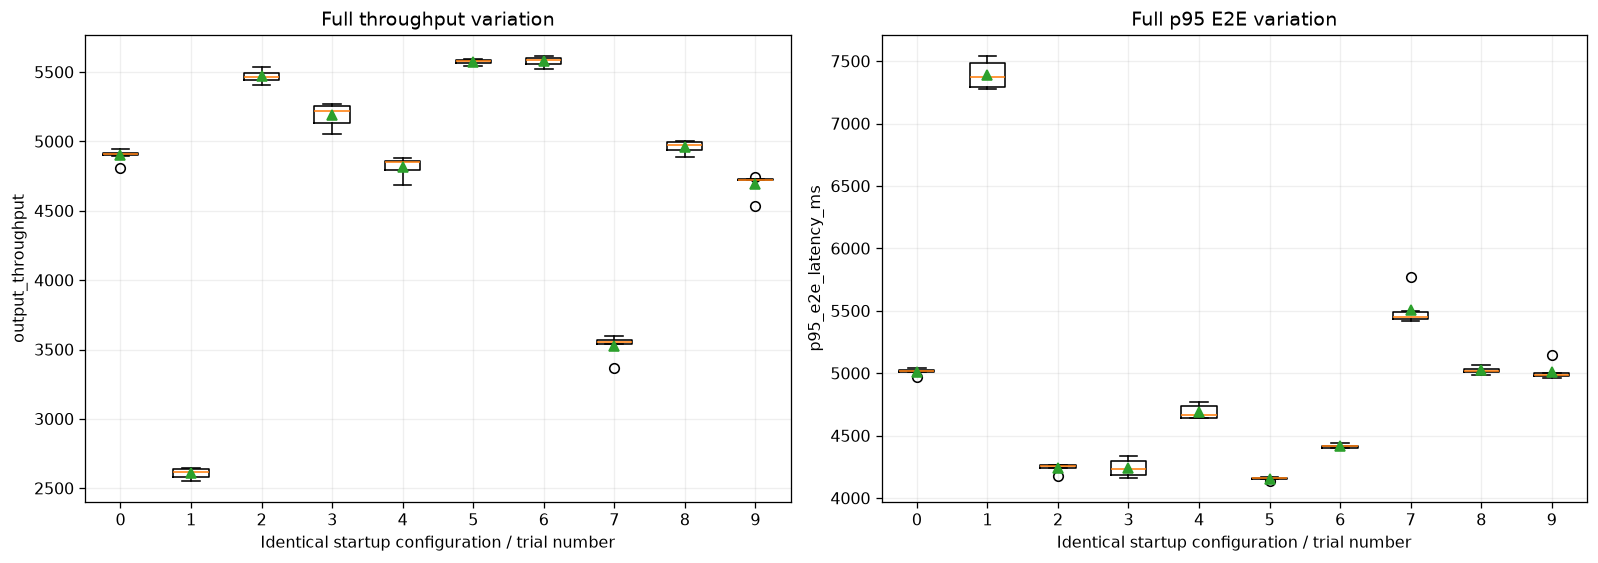

count  median    min   max
target     step                            
e2e        400      48  -3.132 -7.182 0.004
           500      48  -1.455 -4.640 0.554
           1000     48   0.000  0.000 0.000
throughput 400      49  -1.190 -3.609 3.155
           500      49  -2.356 -4.283 0.811
           1000     49   0.881  0.413 0.968

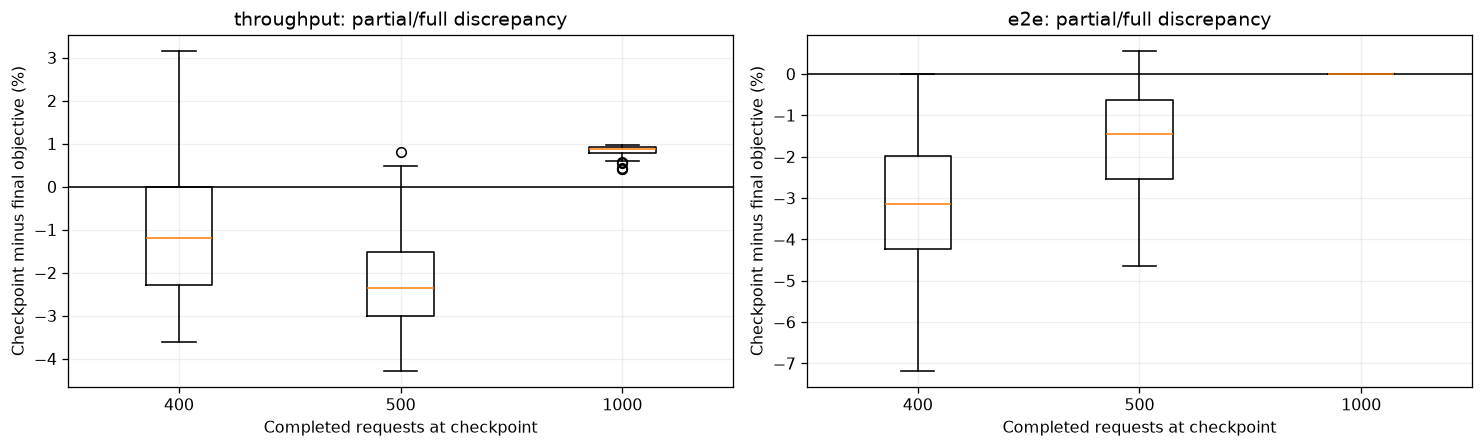

In [7]:
startup = complete[complete.number.lt(10)]
assert startup.groupby("number")["trial/config_id"].nunique().eq(1).all()
repeat_rows = []
for cid, g in startup.groupby("trial/config_id"):
    row = {"startup_trial": int(g.number.iloc[0]), "config_id": cid, "repeats": len(g),
           "max_num_seqs": g["parameters/max_num_seqs"].iloc[0],
           "max_num_batched_tokens": g["parameters/max_num_batched_tokens"].iloc[0]}
    for field, short in [("benchmark/output_throughput", "throughput"), ("benchmark/p95_e2e_latency_ms", "p95_e2e")]:
        values = g[field]
        row[short + "_range_pct_of_median"] = 100 * (values.max() - values.min()) / values.median()
        row[short + "_cv_pct"] = 100 * values.std(ddof=1) / values.mean()
    repeat_rows.append(row)
repeats = pd.DataFrame(repeat_rows).sort_values("startup_trial")
display(repeats)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, field, title in zip(axes, ["benchmark/output_throughput", "benchmark/p95_e2e_latency_ms"], ["Full throughput variation", "Full p95 E2E variation"]):
    values = [startup.loc[startup.number.eq(t), field].to_numpy() for t in range(10)]
    ax.boxplot(values, tick_labels=list(range(10)), showmeans=True)
    ax.set(xlabel="Identical startup configuration / trial number", ylabel=field.removeprefix("benchmark/"), title=title)
fig.tight_layout()
plt.show()
checkpoint_rows = []
for r in complete.to_dict("records"):
    for step in [400, 500, 1000]:
        value = r.get(f"trial/intermediate_values.{step}")
        if value is not None and np.isfinite(value):
            checkpoint_rows.append({"target": r["target"], "step": step, "delta_pct": 100 * (value / r["objective"] - 1)})
checkpoint_delta = pd.DataFrame(checkpoint_rows)
display(checkpoint_delta.groupby(["target", "step"]).delta_pct.agg(["count", "median", "min", "max"]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, target in zip(axes, ["throughput", "e2e"]):
    sub = checkpoint_delta[checkpoint_delta.target.eq(target)]
    ax.boxplot([sub.loc[sub.step.eq(s), "delta_pct"] for s in [400, 500, 1000]], tick_labels=[400, 500, 1000])
    ax.axhline(0, color="black", linewidth=1)
    ax.set(xlabel="Completed requests at checkpoint", ylabel="Checkpoint minus final objective (%)", title=f"{target}: partial/full discrepancy")
fig.tight_layout()
plt.show()

The partial throughput at 1000 completions can differ slightly from the final throughput: the checkpoint denominator ends inside the completion callback, whereas final accounting happens after all tasks finish. That is distinct from fabricated objectives. Prefix metrics also select requests that finished earliest; they do not observe the eventual tail of unfinished requests. Variation and prefix/final differences make the two sub-0.2% pruning decisions too weak to interpret as robust performance distinctions.

## 7. Concurrency pressure and parameter associations

Every run uses **client concurrency 128**. The sampled server `max_num_seqs` is a separate capacity setting. Lower server capacity under the same offered load can increase server-side waiting and reduce throughput. These plots are descriptive because many parameters change together; they cannot show that changing client concurrency alone would improve results.

The benchmark starts its per-request timer after acquiring the client semaphore. Thus E2E includes HTTP/server waiting and generation for active requests, but excludes waiting for a client-side semaphore slot. P95 E2E is not total arrival-to-completion latency for all 1000 queued requests.

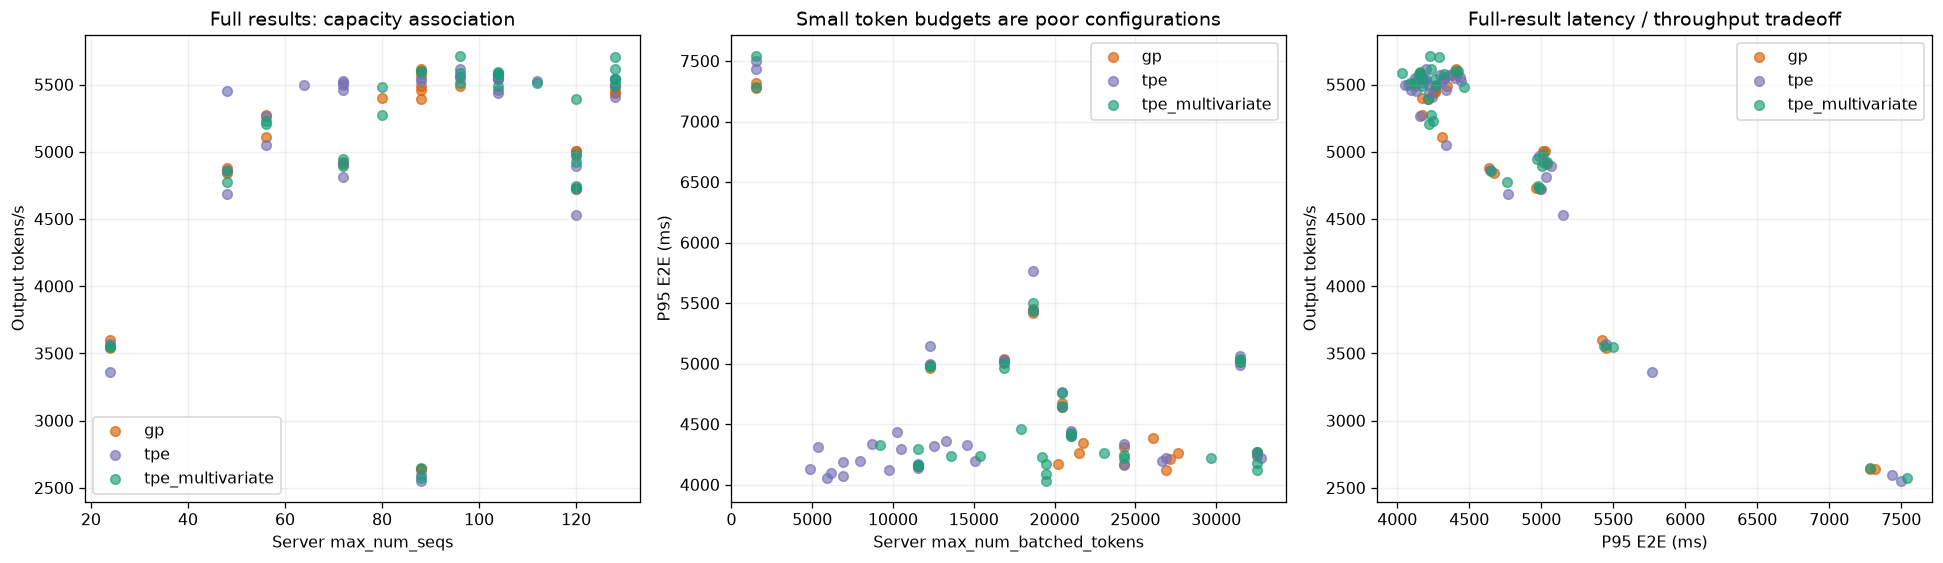

benchmark/output_throughput  \
                                                                        count   
parameters/async_scheduling parameters/graph_mode                               
False                       NONE                                           18   
                            PIECEWISE                                      18   
True                        FULL_AND_PIECEWISE                             37   
                            NONE                                           17   
                            PIECEWISE                                       7   

                                                                       \
                                                     median       min   
parameters/async_scheduling parameters/graph_mode                       
False                       NONE                  4,725.072 3,363.289   
                            PIECEWISE             4,850.226 2,553.904   
True                        FULL_AND_PIECEWISE    5,541.658 5,391.358   
                            NONE                  5,491.339 5,276.405   
                            PIECEWISE             5,230.315 5,052.405   

                                                             \
                                                        max   
parameters/async_scheduling parameters/graph_mode             
False                       NONE                  4,944.000   
                            PIECEWISE             5,006.475   
True                        FULL_AND_PIECEWISE    5,710.270   
                            NONE                  5,613.565   
                            PIECEWISE             5,401.282   

                                                  benchmark/p95_e2e_latency_ms  \
                                                                         count   
parameters/async_scheduling parameters/graph_mode                                
False                       NONE                                            18   
                            PIECEWISE                                       18   
True                        FULL_AND_PIECEWISE                              37   
                            NONE                                            17   
                            PIECEWISE                                        7   

                                                                       \
                                                     median       min   
parameters/async_scheduling parameters/graph_mode                       
False                       NONE                  5,026.966 4,961.785   
                            PIECEWISE             5,019.683 4,640.576   
True                        FULL_AND_PIECEWISE    4,196.711 4,033.813   
                            NONE                  4,266.933 4,178.819   
                            PIECEWISE             4,219.945 4,160.690   

                                                             
                                                        max  
parameters/async_scheduling parameters/graph_mode            
False                       NONE                  5,767.639  
                            PIECEWISE             7,538.520  
True                        FULL_AND_PIECEWISE    4,436.998  
                            NONE                  4,463.704  
                            PIECEWISE             4,337.229

,run_id,target,number,state,parameters/max_num_seqs,parameters/max_num_batched_tokens,parameters/async_scheduling,trial/intermediate_values.400,objective
61,8gp1fym7,e2e,1,COMPLETE,88,1536,False,"7,156.045","7,314.807"
21,cvzosd1r,throughput,1,COMPLETE,88,1536,False,"2,512.106","2,576.891"
32,cvzosd1r,throughput,12,PRUNED,72,1024,True,"2,345.372",NaN
101,g84ks3ri,e2e,1,COMPLETE,88,1536,False,"7,495.918","7,500.681"
41,qyu0g3ke,throughput,1,COMPLETE,88,1536,False,"2,530.889","2,595.132"
81,s0k095o0,e2e,1,COMPLETE,88,1536,False,"7,183.483","7,286.345"
92,s0k095o0,e2e,12,PRUNED,72,1024,True,"7,995.674",NaN
1,zbyjlkdk,throughput,1,COMPLETE,88,1536,False,"2,553.035","2,641.889"


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for sampler, g in complete.groupby("sampler"):
    axes[0].scatter(g["parameters/max_num_seqs"], g["benchmark/output_throughput"], label=sampler, color=colors[sampler], alpha=0.65)
    axes[1].scatter(g["parameters/max_num_batched_tokens"], g["benchmark/p95_e2e_latency_ms"], label=sampler, color=colors[sampler], alpha=0.65)
    axes[2].scatter(g["benchmark/p95_e2e_latency_ms"], g["benchmark/output_throughput"], label=sampler, color=colors[sampler], alpha=0.65)
axes[0].set(xlabel="Server max_num_seqs", ylabel="Output tokens/s", title="Full results: capacity association")
axes[1].set(xlabel="Server max_num_batched_tokens", ylabel="P95 E2E (ms)", title="Small token budgets are poor configurations")
axes[2].set(xlabel="P95 E2E (ms)", ylabel="Output tokens/s", title="Full-result latency / throughput tradeoff")
for ax in axes: ax.legend()
fig.tight_layout()
plt.show()
display(complete.groupby(["parameters/async_scheduling", "parameters/graph_mode"])[["benchmark/output_throughput", "benchmark/p95_e2e_latency_ms"]].agg(["count", "median", "min", "max"]))
# These outliers are the same effective configuration across both objective studies.
display(df[(df.sampler.eq("tpe_multivariate") & df.number.eq(12)) | df.number.eq(1)][
    ["run_id", "target", "number", "state", "parameters/max_num_seqs", "parameters/max_num_batched_tokens",
     "parameters/async_scheduling", "trial/intermediate_values.400", "objective"]])

Two conspicuously poor settings recur across objectives: startup trial 1 has a 1536-token batch budget, and multivariate trial 12 has a 1024-token budget. This points to configuration-dependent slowdowns rather than a hidden request failure. The GP `max_num_seqs=8` tail is another clear capacity bottleneck under this workload. Other changed settings confound attribution.

None of the six histories contains draft acceptance, accepted tokens per speculative step, preemptions, queue depth, GPU utilization/memory samples, actual output token totals, mean/median/p99 E2E, or per-request timings. Their run-file inventories also contain no `output.log`. A working draft head is configured identically in all six, but these artifacts cannot establish its acceptance or correctness on every trial.

## 8. Recommended next checks, without changing these results

1. Treat the GP tail as an optimizer/pruning interaction. Re-evaluate the best COMPLETE GP configuration and a selected seq=8 candidate with pruning disabled; do not assign artificial penalty values to the existing PRUNED trials.
2. Re-run multivariate throughput trial 17 and E2E trial 16 to completion, with repeats. Their sub-0.2% prune margins do not establish robust inferiority.
3. Compare the best fixed native configurations with DFlash on/off and the **same pinned target**, request manifest, output length, concurrency and measurement settings. These six DFlash-only runs cannot show a benefit/regression versus baseline.
4. Capture native vLLM logs and draft acceptance metrics, actual/re-tokenized output totals, mean/median/p99 latency and preemptions. The repository JSONL benchmark records may contain richer metrics than W&B's selected `Measurement` fields; inspect those records on the VM.
5. If testing client-concurrency impact, hold native engine settings fixed and compare 128 with lower client concurrency. Do not infer this counterfactual from changing `max_num_seqs` inside these studies.
6. Use history rows or `best_or_pareto_trials` to select configurations. Avoid joining the last W&B summary parameters to a stale benchmark value.

The analysis changes no study state, pruning settings, optimizer implementation, or benchmark semantics.

## 9. Inspect any individual trial

Change `RUN_ID` and `TRIAL` to inspect a compact trial record from the saved evidence. No run-summary carry-forward is used.

In [9]:
RUN_ID = "8gp1fym7"
TRIAL = 16
selected = df[df.run_id.eq(RUN_ID) & df.number.eq(TRIAL)].iloc[0]
compact = {k: v for k, v in selected.items()
           if k.startswith(("parameters/", "benchmark/", "requests/", "objective/", "trial/intermediate_values."))
           and v is not None and not (isinstance(v, float) and np.isnan(v))}
display({"run": RUN_ID, "trial": TRIAL, "state": selected.state, "config_id": selected["trial/config_id"], **compact})

{'run': '8gp1fym7',
 'trial': 16,
 'state': 'PRUNED',
 'config_id': '6fda77362fca471b',
 'requests/total_requests': np.float64(400.0),
 'parameters/kv_cache_dtype': 'auto',
 'parameters/max_num_seqs': np.int64(8),
 'parameters/enable_prefix_caching': np.True_,
 'parameters/max_num_batched_tokens': np.int64(30208),
 'parameters/async_scheduling': np.True_,
 'parameters/graph_mode': 'FULL_AND_PIECEWISE',
 'requests/failed': np.float64(0.0),
 'requests/completed': np.float64(400.0),
 'parameters/performance_mode': 'balanced',
 'trial/intermediate_values.400': np.float64(11582.442413199351),
 'parameters/graph_capture_profile': 'powers',
 'requests/planned_requests': np.float64(1000.0),
 'parameters/attention_backend': 'FLASH_ATTN',
 'parameters/gpu_memory_utilization': np.float64(0.75)}

## 10. Why the non-speculative GP study looks better

Baseline: [B-vllm-c128-throughput-gp-s11-r1 / 2f2gjeil](https://forge.coreweave.com/wandb/maorblumberg-tel-aviv-university/inference-optimization/runs/2f2gjeil).

**Observed:** baseline best trial 17 achieves **7,258.91 output tokens/s**, compared with DFlash GP best trial 6 at **5,613.57 tokens/s**. Baseline is **29.31% higher**; equivalently DFlash GP is **22.67% lower**. Even the best DFlash throughput result across the three requested samplers (5,710.27) is 21.33% below the baseline winner. These are best-of-study comparisons with different winning configurations.

**This is not a clean DFlash on/off comparison.** The table below explicitly audits the confounders. Placeholder baseline revision fields cannot establish that the target weights/tokenizer match the pinned DFlash run. Same model name is insufficient. The baseline records no speculative settings, and the saved native commands contain no speculative flags.

In [10]:
baseline_run = snapshot["baseline_runs"][0]
baseline_cfg = baseline_run["config"]
dflash_gp_run = next(r for r in runs if r["id"] == "zbyjlkdk")
dflash_cfg = dflash_gp_run["config"]

def comparison_fields(cfg):
    env = cfg["environment"]
    return {
        "model name": cfg.get("target_model"),
        "target revision": env.get("model_revision"),
        "tokenizer revision": env.get("tokenizer_revision"),
        "vLLM package version": env.get("package_versions", {}).get("vllm"),
        "CUDA version": env.get("cuda_version"),
        "driver version": env.get("driver_version"),
        "GPU recorded": env.get("gpu_type"),
        "client concurrency": cfg["concurrency"],
        "request count": cfg["workload"]["num_prompts"],
        "input/output lengths": f"{cfg['workload']['random_input_len']} / {cfg['workload']['random_output_len']}",
        "workload seed": cfg["workload"]["seed"],
        "request fingerprint": env.get("requests_sha256"),
        "GP seed": cfg["sampler_settings"]["seed"],
        "GP startup trials": cfg["sampler_settings"]["n_startup_trials"],
        "trial budget": cfg["budget_trials"],
        "pruner": cfg["pruner_class"],
        "expanded choices": json.dumps(cfg["expanded_choices"], sort_keys=True),
        "fixed server settings": json.dumps(env.get("fixed_server", {}), sort_keys=True),
    }
a = comparison_fields(baseline_cfg)
b = comparison_fields(dflash_cfg)
contract_comparison = pd.DataFrame({"baseline": a, "DFlash GP": b})
contract_comparison["recorded_equal"] = contract_comparison.baseline.eq(contract_comparison["DFlash GP"])
display(contract_comparison)

baseline_records = []
for raw in baseline_run["history"]:
    baseline_records.append({**raw, "run_id": baseline_run["id"], "number": int(raw["trial/number"]),
                             "state": raw["trial/state"], "objective": raw.get("objective/output_throughput")})
base = pd.DataFrame(baseline_records).sort_values("number")
assert len(base) == 20 and base.state.eq("COMPLETE").all()
assert base["benchmark/completed"].eq(896).all() and base["benchmark/failed"].eq(0).all()
assert np.isfinite(base.objective).all()
print("Baseline completed trials:", len(base), "; recorded failed requests:", base["benchmark/failed"].sum())

,baseline,DFlash GP,recorded_equal
model name,Qwen/Qwen3.5-4B,Qwen/Qwen3.5-4B,True
target revision,REPLACE_WITH_PHASE_B_MODEL_COMMIT,851bf6e806efd8d0a36b00ddf55e13ccb7b8cd0a,False
tokenizer revision,REPLACE_WITH_PHASE_B_MODEL_COMMIT,851bf6e806efd8d0a36b00ddf55e13ccb7b8cd0a,False
vLLM package version,0.30.0,0.31.0,False
CUDA version,REPLACE_WITH_CUDA_VERSION,13.0,False
driver version,REPLACE_WITH_DRIVER_VERSION,580.173.02,False
GPU recorded,NVIDIA H100,NVIDIA H100 80GB HBM3,False
client concurrency,128,128,True
request count,896,1000,False
input/output lengths,512 / 128,512 / 128,True


Baseline completed trials: 20 ; recorded failed requests: 0


### Best-of-study behavior and the GP feedback difference

The baseline completes all 20 trials, so GP receives 20 objective observations and can revise its beliefs about bad regions. DFlash GP completes only 13; its last six attempts are pruned at `max_num_seqs=8`, adding no completed observations to the GP model.

The baseline finds a different high-throughput region: its winner uses `max_num_seqs=128`, full-and-piecewise graphs, async scheduling, FP8 KV cache, explicit FLASHINFER, a 32768 token budget and 0.75 memory utilization. That **exact winner is absent from all six DFlash histories**. Hence the best-value gap combines search trajectory and per-configuration performance; it is not a measured penalty from attaching a draft head to the same winning configuration.

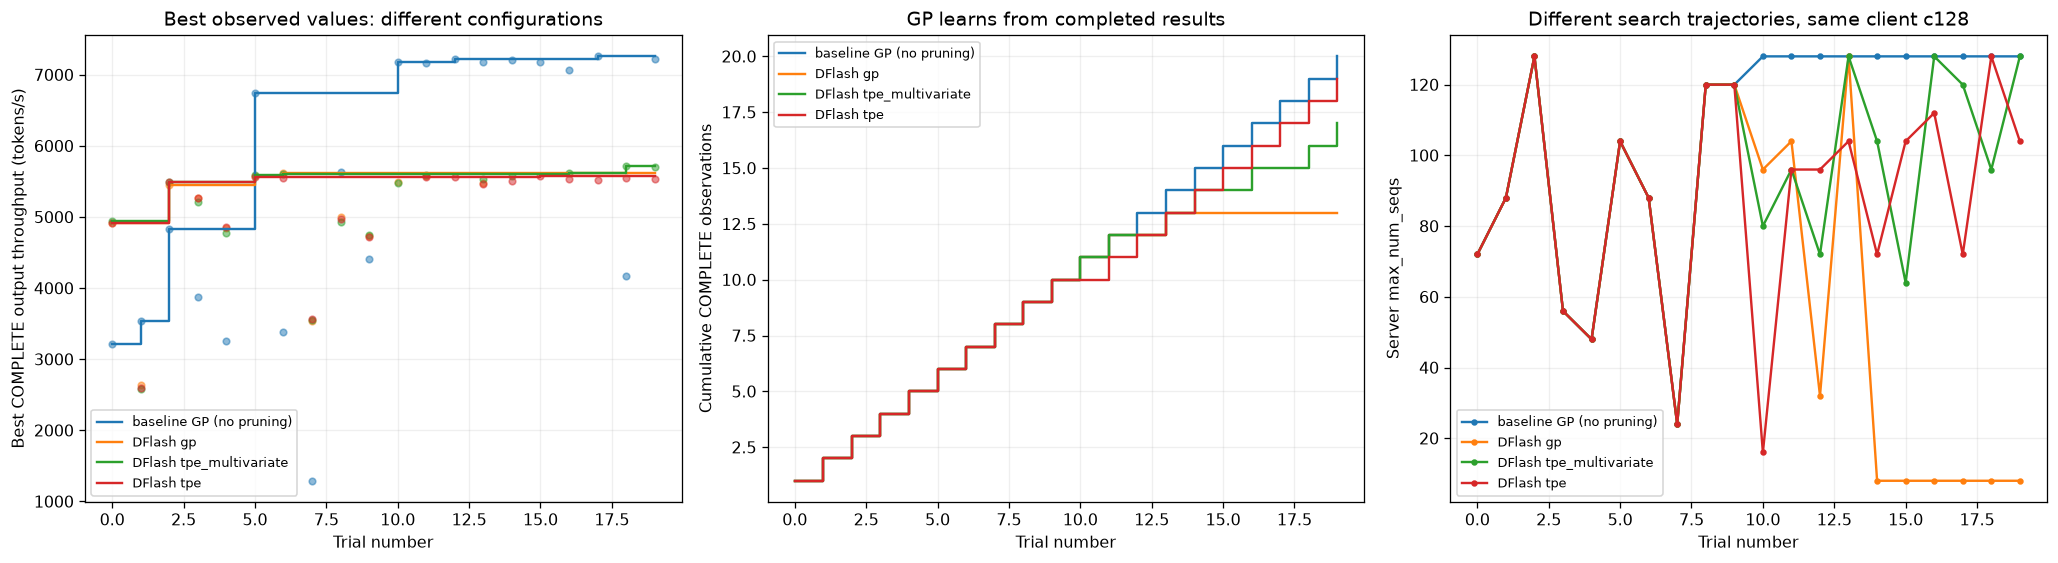

,run,best_trial,output_tok_s,difference_vs_baseline_pct,p95_e2e_ms,max_num_seqs,graph,attention,KV dtype
0,baseline GP (no pruning),17,"7,258.913",0.000,"2,327.553",128,FULL_AND_PIECEWISE,FLASHINFER,fp8
1,DFlash gp,6,"5,613.565",-22.667,"4,411.515",88,NONE,auto,fp8
2,DFlash tpe_multivariate,18,"5,710.270",-21.334,"4,226.784",96,FULL_AND_PIECEWISE,FLASH_ATTN,auto
3,DFlash tpe,15,"5,571.983",-23.239,"4,362.701",104,FULL_AND_PIECEWISE,FLASH_ATTN,fp8


{'baseline winner parameters': {'max_num_seqs': np.int64(128),
  'performance_mode': 'interactivity',
  'async_scheduling': np.True_,
  'gpu_memory_utilization': np.float64(0.75),
  'max_num_batched_tokens': np.int64(32768),
  'attention_backend': 'FLASHINFER',
  'enable_prefix_caching': np.False_,
  'graph_capture_profile': 'dense',
  'kv_cache_dtype': 'fp8',
  'graph_mode': 'FULL_AND_PIECEWISE'}}

In [11]:
comparative_runs = [("baseline GP (no pruning)", base)]
for run in runs:
    if run["config"]["target"] == "throughput":
        comparative_runs.append(("DFlash " + run["config"]["sampler"], df[df.run_id.eq(run["id"])].sort_values("number")))
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for label, group in comparative_runs:
    values = group.objective.where(group.state.eq("COMPLETE"))
    line = axes[0].step(group.number, values.cummax().ffill(), where="post", label=label)[0]
    color = line.get_color()
    axes[0].scatter(group.number, values, s=17, color=color, alpha=0.5)
    axes[1].step(group.number, group.state.eq("COMPLETE").cumsum(), where="post", color=color, label=label)
    axes[2].plot(group.number, group["parameters/max_num_seqs"], marker=".", color=color, label=label)
axes[0].set(xlabel="Trial number", ylabel="Best COMPLETE output throughput (tokens/s)", title="Best observed values: different configurations")
axes[1].set(xlabel="Trial number", ylabel="Cumulative COMPLETE observations", title="GP learns from completed results")
axes[2].set(xlabel="Trial number", ylabel="Server max_num_seqs", title="Different search trajectories, same client c128")
for ax in axes: ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

best_comparison = []
for label, group in comparative_runs:
    completed_group = group[group.state.eq("COMPLETE")]
    winner = completed_group.loc[completed_group.objective.idxmax()]
    best_comparison.append({"run": label, "best_trial": int(winner.number), "output_tok_s": winner.objective,
                            "difference_vs_baseline_pct": 100 * (winner.objective / base.objective.max() - 1),
                            "p95_e2e_ms": winner["benchmark/p95_e2e_latency_ms"],
                            "max_num_seqs": winner["parameters/max_num_seqs"],
                            "graph": winner["parameters/graph_mode"], "attention": winner["parameters/attention_backend"],
                            "KV dtype": winner["parameters/kv_cache_dtype"]})
display(pd.DataFrame(best_comparison))
baseline_best = base.loc[base.objective.idxmax()]
assert baseline_best["trial/config_id"] not in set(df["trial/config_id"])
display({"baseline winner parameters": {k.removeprefix("parameters/"): v for k, v in baseline_best.items()
                                        if k.startswith("parameters/") and v is not None
                                        and not (isinstance(v, float) and np.isnan(v))}})

## 11. Hold the sampled engine configuration fixed

Ten baseline configurations match DFlash configurations exactly at the **native sampled engine setting** level, excluding the deliberately changed speculative config. The native settings are reconstructed and compared, rather than trusting only a config ID. Model revision, runtime, workload size and request fingerprint are still different or unverified, so the following is a cross-run association, **not a causal DFlash speedup measurement**.

The first ten DFlash trials all complete before pruning can start. Their mixed performance therefore cannot be explained by the later GP/pruning loop alone.

,baseline_trial,server_max_num_seqs,graph,async,attention,baseline_tok_s,dflash_tok_s,delta_throughput_pct
0,0,72,NONE,False,FLASHINFER,"3,219.863","4,922.758",52.887
1,1,88,PIECEWISE,False,auto,"3,536.151","2,641.889",-25.289
2,2,128,NONE,True,auto,"4,828.077","5,447.174",12.823
3,3,56,PIECEWISE,True,auto,"3,880.394","5,270.713",35.829
4,4,48,PIECEWISE,False,FLASH_ATTN,"3,256.263","4,839.962",48.635
5,5,104,FULL_AND_PIECEWISE,True,FLASH_ATTN,"6,748.481","5,578.963",-17.330
6,6,88,NONE,True,auto,"3,383.675","5,613.565",65.901
7,7,24,NONE,False,auto,"1,291.239","3,537.131",173.933
8,8,120,PIECEWISE,False,FLASHINFER,"5,632.395","5,005.545",-11.129
9,9,120,NONE,False,FLASHINFER,"4,410.267","4,728.583",7.218


Same-native-setting comparisons, DFlash GP: faster 7 ; slower 3


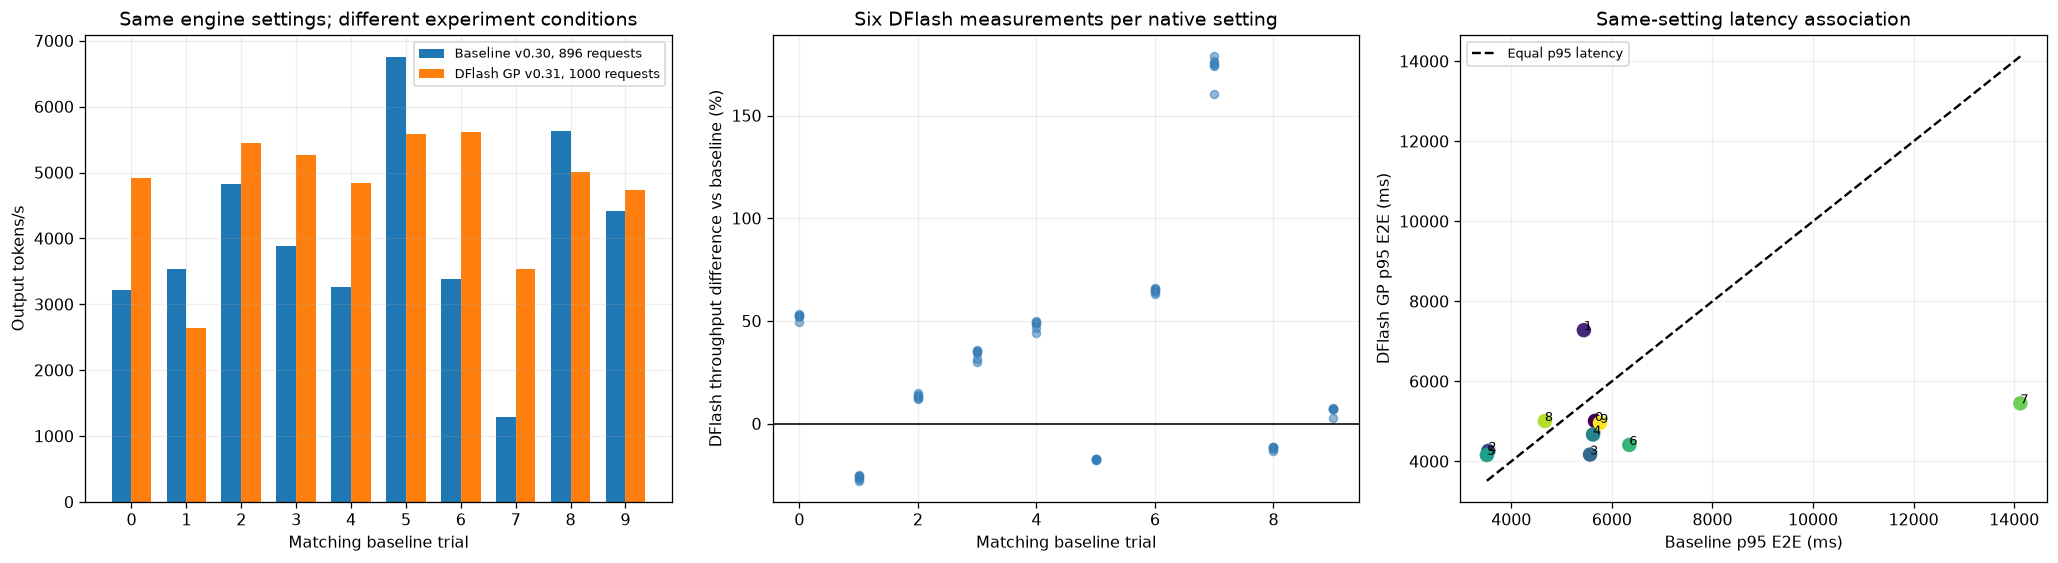

In [12]:
def sampled_native_signature(raw):
    native = {k.removeprefix("trial/config."): v for k, v in raw.items()
              if k.startswith("trial/config.") and v is not None
              and not (isinstance(v, float) and np.isnan(v))}
    return json.dumps(native, sort_keys=True)

baseline_by_native = {sampled_native_signature(raw): raw for raw in baseline_run["history"]}
matched = []
for run in runs:
    for raw in run["history"]:
        old = baseline_by_native.get(sampled_native_signature(raw))
        if old is None or raw["trial/state"] != "COMPLETE":
            continue
        matched.append({"dflash_run": run["id"], "sampler": run["config"]["sampler"], "target": run["config"]["target"],
                        "baseline_trial": old["trial/number"], "dflash_trial": raw["trial/number"],
                        "config_id": old["trial/config_id"], "baseline_tok_s": old["benchmark/output_throughput"],
                        "dflash_tok_s": raw["benchmark/output_throughput"],
                        "baseline_p95_e2e_ms": old["benchmark/p95_e2e_latency_ms"],
                        "dflash_p95_e2e_ms": raw["benchmark/p95_e2e_latency_ms"],
                        "delta_throughput_pct": 100 * (raw["benchmark/output_throughput"] / old["benchmark/output_throughput"] - 1),
                        "server_max_num_seqs": old["parameters/max_num_seqs"],
                        "graph": old["parameters/graph_mode"], "async": old["parameters/async_scheduling"],
                        "attention": old["parameters/attention_backend"]})
matched = pd.DataFrame(matched)
assert len(matched) == 60 and matched.groupby("dflash_run").size().eq(10).all()
matched_gp = matched[matched.dflash_run.eq("zbyjlkdk")].sort_values("baseline_trial")
display(matched_gp[["baseline_trial", "server_max_num_seqs", "graph", "async", "attention", "baseline_tok_s", "dflash_tok_s", "delta_throughput_pct"]])
print("Same-native-setting comparisons, DFlash GP: faster", int(matched_gp.delta_throughput_pct.gt(0).sum()),
      "; slower", int(matched_gp.delta_throughput_pct.lt(0).sum()))
assert matched_gp.delta_throughput_pct.gt(0).sum() == 7

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
positions = np.arange(len(matched_gp))
axes[0].bar(positions - 0.18, matched_gp.baseline_tok_s, width=0.36, label="Baseline v0.30, 896 requests")
axes[0].bar(positions + 0.18, matched_gp.dflash_tok_s, width=0.36, label="DFlash GP v0.31, 1000 requests")
axes[0].set(xticks=positions, xticklabels=matched_gp.baseline_trial.astype(int), xlabel="Matching baseline trial", ylabel="Output tokens/s", title="Same engine settings; different experiment conditions")
axes[0].legend(fontsize=8)
for trial, group in matched.groupby("baseline_trial"):
    axes[1].scatter([trial] * len(group), group.delta_throughput_pct, color="#377eb8", alpha=0.55, s=25)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set(xlabel="Matching baseline trial", ylabel="DFlash throughput difference vs baseline (%)", title="Six DFlash measurements per native setting")
axes[2].scatter(matched_gp.baseline_p95_e2e_ms, matched_gp.dflash_p95_e2e_ms, c=matched_gp.baseline_trial, cmap="viridis", s=65)
lo = min(matched_gp.baseline_p95_e2e_ms.min(), matched_gp.dflash_p95_e2e_ms.min())
hi = max(matched_gp.baseline_p95_e2e_ms.max(), matched_gp.dflash_p95_e2e_ms.max())
axes[2].plot([lo, hi], [lo, hi], "k--", label="Equal p95 latency")
for row in matched_gp.itertuples(): axes[2].annotate(str(int(row.baseline_trial)), (row.baseline_p95_e2e_ms, row.dflash_p95_e2e_ms), fontsize=8)
axes[2].set(xlabel="Baseline p95 E2E (ms)", ylabel="DFlash GP p95 E2E (ms)", title="Same-setting latency association")
axes[2].legend(fontsize=8)
fig.tight_layout()
plt.show()

**Observed configuration interaction:** matched trial 5 (async scheduling, full-and-piecewise graphs, auto KV dtype, FLASH_ATTN, server capacity 104) drops from 6,748.49 to 5,578.96 tokens/s (**−17.33%**). But trial 0 improves from 3,219.86 to 4,922.76 (**+52.89%**) and seven of ten matched GP configurations improve overall. Trial 1 and trial 8 also regress. This pattern supports configuration/runtime-dependent behavior; it does not support claiming that DFlash is universally slower at concurrency 128.

The baseline's best region is also better than its own initial configurations: it reaches about 7.2k tokens/s after trial 10. The DFlash GP study never evaluates that exact winner and then loses six trials to pruning. Both a search difference and cross-run performance differences matter. Neither contribution can be isolated numerically from these runs.

## 12. Richer baseline metrics and token-accounting checks

The local baseline JSONL artifact contains actual benchmark duration, mean/median/p95/p99 latency and re-tokenized output totals that were not logged in W&B's selected Measurement fields. All 20 JSONL rows are matched against the baseline W&B objectives **and native configs** before using them. The entire local evidence is embedded in the adjacent snapshot; no dependency on the original file remains.

Equivalent richer DFlash records have not been supplied, so we cannot plot a paired mean-latency or actual-token comparison. Do not invent DFlash mean latency from its p95, or infer benchmark duration from allocated GPU seconds.

,trial,duration,output_throughput,mean_e2e_latency_ms,median_e2e_latency_ms,p95_e2e_latency_ms,p99_e2e_latency_ms,mean_tpot_ms,retokenized_difference_pct
0,0,35.619,"3,219.863","4,760.238","5,336.265","5,665.354","5,671.634",19.890,0.398
1,1,32.433,"3,536.151","4,420.727","4,162.604","5,444.508","7,075.675",23.156,0.396
2,2,23.754,"4,828.077","3,379.391","3,380.090","3,545.024","3,682.765",22.214,0.383
3,3,29.556,"3,880.394","4,043.527","3,697.158","5,566.922","5,676.316",12.042,0.397
4,4,35.221,"3,256.263","4,756.013","5,280.749","5,626.905","5,766.261",12.934,0.392
5,5,16.995,"6,748.481","2,347.768","2,082.165","3,516.185","3,980.184",12.747,0.398
6,6,33.895,"3,383.675","4,464.132","3,523.235","6,347.528","6,379.055",21.918,0.386
7,7,88.820,"1,291.239","11,770.811","11,741.382","14,122.330","14,180.909",17.168,0.405
8,8,20.362,"5,632.395","2,749.152","2,653.790","4,668.893","4,931.443",16.998,0.393
9,9,26.005,"4,410.267","3,513.192","3,352.455","5,765.861","5,953.663",23.918,0.394


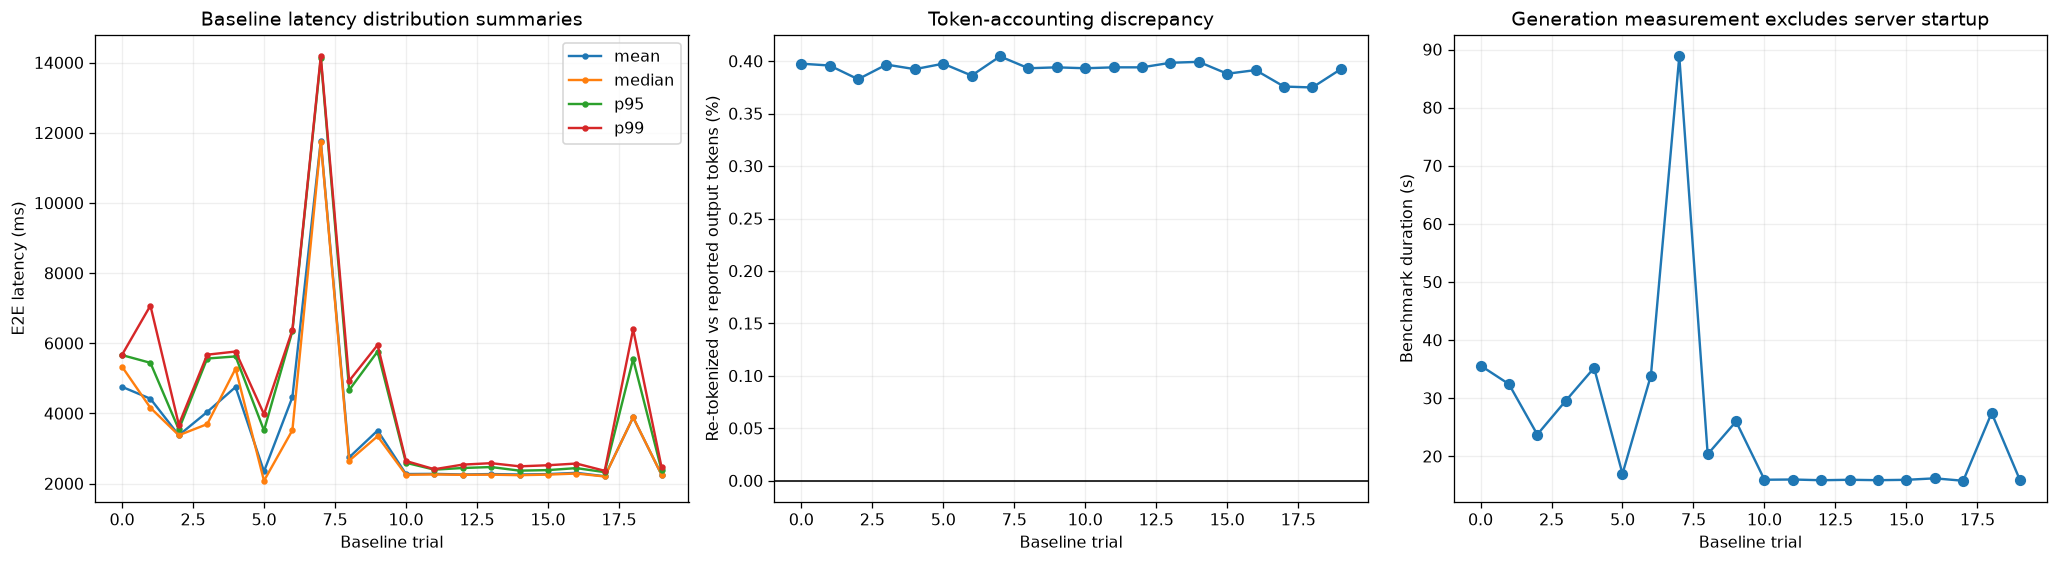

Baseline winner detailed metrics:


,duration,request_throughput,mean_e2e_latency_ms,median_e2e_latency_ms,p95_e2e_latency_ms,p99_e2e_latency_ms,mean_ttft_ms,mean_tpot_ms,retokenized_difference_pct
17,15.800,56.710,"2,211.280","2,203.987","2,327.553","2,365.959",723.313,11.716,0.376


Max absolute re-tokenization discrepancy (%): 0.4045758928571397


In [13]:
local_evidence = snapshot["baseline_local_evidence"]
local_results = []
for raw, record in zip(sorted(baseline_run["history"], key=lambda r: r["trial/number"]), local_evidence["records"]):
    args = record["config"]["server_args"]
    results = record["results"]
    assert np.isclose(results["output_throughput"], raw["objective/output_throughput"], atol=1e-8, rtol=0)
    assert args["max_num_seqs"] == raw["parameters/max_num_seqs"]
    assert args["max_num_batched_tokens"] == raw["parameters/max_num_batched_tokens"]
    assert args["kv_cache_dtype"] == raw["parameters/kv_cache_dtype"]
    assert args["attention_backend"] == raw["parameters/attention_backend"]
    assert args["performance_mode"] == raw["parameters/performance_mode"]
    assert np.isclose(args["gpu_memory_utilization"], raw["parameters/gpu_memory_utilization"])
    graph = json.loads(args["compilation_config"])
    assert graph["cudagraph_mode"] == raw["parameters/graph_mode"]
    assert graph.get("cudagraph_capture_sizes") == raw.get("trial/config.compilation_config.cudagraph_capture_sizes")
    assert bool(args.get("async_scheduling", False)) == raw["parameters/async_scheduling"]
    assert bool(args.get("enable_prefix_caching", False)) == raw["parameters/enable_prefix_caching"]
    assert args.get("enable_chunked_prefill") == raw["trial/config.enable_chunked_prefill"]
    assert not any("speculative" in key for key in args)
    assert results["completed"] == results["total_requests"] == 896
    assert results["failed"] == 0 and results["benchmark_valid"] is True
    assert results["total_output_tokens"] == 896 * 128
    assert np.isclose(results["output_throughput"], results["total_output_tokens"] / results["duration"])
    local_results.append({"trial": raw["trial/number"], **results,
                          "retokenized_difference_pct": 100 * (results["total_output_tokens_retokenized"] / results["total_output_tokens"] - 1)})
base_rich = pd.DataFrame(local_results)
display(base_rich[["trial", "duration", "output_throughput", "mean_e2e_latency_ms", "median_e2e_latency_ms",
                   "p95_e2e_latency_ms", "p99_e2e_latency_ms", "mean_tpot_ms", "retokenized_difference_pct"]])
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for metric, label in [("mean_e2e_latency_ms", "mean"), ("median_e2e_latency_ms", "median"), ("p95_e2e_latency_ms", "p95"), ("p99_e2e_latency_ms", "p99")]:
    axes[0].plot(base_rich.trial, base_rich[metric], marker=".", label=label)
axes[0].set(xlabel="Baseline trial", ylabel="E2E latency (ms)", title="Baseline latency distribution summaries")
axes[0].legend()
axes[1].plot(base_rich.trial, base_rich.retokenized_difference_pct, marker="o")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set(xlabel="Baseline trial", ylabel="Re-tokenized vs reported output tokens (%)", title="Token-accounting discrepancy")
axes[2].plot(base_rich.trial, base_rich.duration, marker="o")
axes[2].set(xlabel="Baseline trial", ylabel="Benchmark duration (s)", title="Generation measurement excludes server startup")
fig.tight_layout()
plt.show()
print("Baseline winner detailed metrics:")
display(base_rich[base_rich.trial.eq(int(baseline_best.number))][["duration", "request_throughput", "mean_e2e_latency_ms",
    "median_e2e_latency_ms", "p95_e2e_latency_ms", "p99_e2e_latency_ms", "mean_ttft_ms", "mean_tpot_ms", "retokenized_difference_pct"]])
print("Max absolute re-tokenization discrepancy (%):", base_rich.retokenized_difference_pct.abs().max())

The baseline winner completes 896 requests in **15.80 s** with mean E2E **2,211 ms**, p95 **2,328 ms**, and p99 **2,366 ms**. Reported output totals are consistent with 896×128 and the throughput denominator. Re-tokenized output totals provide a useful sanity check, but do not establish exact token counts or generated-text quality; matching checks are needed for DFlash.

The baseline's recorded `concurrency` metric, when present, is derived from throughput and request latency rather than sampled server queue telemetry. It cannot establish a preemption/queue-depth explanation.

## 13. Conclusions from the baseline comparison

**What the evidence supports:**

- The older non-speculative GP study achieved a substantially better **best observed** configuration, with all 20 trials completing. The current GP/pruner loop limits exploration and is a concrete contributing search problem.
- The gap exists in some matching startup configurations before any pruning, so the GP loop is **not a complete explanation**. Other matching configurations improve with the newer DFlash setup. This points to a configuration-dependent change across experiments.
- The experiments differ in vLLM version (0.30.0 versus 0.31.0), request count/manifest (896 versus 1000), GP startup count (8 versus 10), pruning, and unverified target/tokenizer revision. Runtime/default-kernel changes, actual target differences, speculative overhead and workload transients remain possible explanations. Their individual effects are unmeasured.
- Nothing here establishes that client concurrency 128 alone broke DFlash: both experiments use 128, and multiple native settings improve in the DFlash runs.

**Smallest decisive follow-up:** on the same vLLM 0.31.0 environment and pinned target snapshot, replay baseline winner trial 17 and shared native trial 5 with **DFlash off/on**, identical 1000-request manifests, pruning disabled and several repeats. Record full latency summaries, actual/re-tokenized token totals and draft acceptance. Testing the same settings on vLLM 0.30.0 without DFlash would separately measure the version change. Verify the old snapshot from VM download metadata before claiming its weights are identical.

No optimizer or benchmark code has been changed by this investigation.

## 14. TRT-LLM run audit: is the high throughput flawed?

Run: [B-trtllm-c128-throughput-gp-s11-r1-pruner-median / yuvhs01s](https://forge.coreweave.com/wandb/maorblumberg-tel-aviv-university/inference-optimization/runs/yuvhs01s).

**No throughput arithmetic or recorded request-completion flaw was found.** Its best COMPLETE trial is 10: **7,623.10 output tokens/s**, 1000/1000 successful requests, 128,000 reported output tokens over **16.7911 s**. Re-tokenization gives 127,934 tokens (−0.0516%), far too small to explain the gap versus DFlash GP.

All 13 complete JSONL records are matched to W&B objectives and resolved native YAML settings below. The same **request fingerprint** is recorded in TRT and DFlash; both use 1000 requests, input/output lengths 512/128 and client concurrency 128. Their broader workload hashes differ because model/runtime metadata differs. This is much stronger workload evidence than the older 896-request baseline, though the TRT target/tokenizer revision is still a placeholder and cannot prove equal weights.

`results.backend="vllm"` names the shared OpenAI-compatible benchmark client, not the serving framework. The native command is `trtllm-serve`; `FrameworkSpec.benchmark_backend` defaults to `vllm` in `src/llm_optimizer/predefined/framework.py`. This label is not evidence that the wrong server ran.

In [14]:
trt_run = snapshot["trt_runs"][0]
trt_cfg = trt_run["config"]
trt_rows = sorted(trt_run["history"], key=lambda r: r["trial/number"])
trt_completed = [r for r in trt_rows if r["trial/state"] == "COMPLETE"]
trt_pruned = [r for r in trt_rows if r["trial/state"] == "PRUNED"]
trt_evidence = snapshot["trt_local_evidence"]
assert len(trt_rows) == 20 and len(trt_completed) == len(trt_evidence["records"]) == 13
assert len(trt_pruned) == 7
assert not any(r.get("trial/failure_reason") for r in trt_rows)
assert trt_cfg["environment"]["requests_sha256"] == dflash_cfg["environment"]["requests_sha256"]

def flatten_native(settings, prefix=""):
    output = {}
    for key, value in settings.items():
        path = prefix + key
        if isinstance(value, dict):
            output.update(flatten_native(value, path + "."))
        else:
            output[path] = value
    return output

trt_rich_rows = []
for trial, record in zip(trt_completed, trt_evidence["records"]):
    result = record["results"]
    args = record["config"]["server_args"]
    nested = trt_evidence["resolved_yaml_by_basename"][Path(args["config"]).name]
    native = {**{k: v for k, v in args.items() if k != "config"}, **nested}
    for key, value in flatten_native(native).items():
        assert trial.get("trial/config." + key) == value, (trial["trial/number"], key)
    assert record["cmd"].startswith("trtllm-serve ")
    assert np.isclose(result["output_throughput"], trial["objective/output_throughput"], atol=1e-8, rtol=0)
    assert result["completed"] == result["total_requests"] == 1000
    assert result["failed"] == 0 and result["benchmark_valid"] is True
    assert result["total_output_tokens"] == 1000 * 128
    assert np.isclose(result["output_throughput"], result["total_output_tokens"] / result["duration"])
    trt_rich_rows.append({"trial": trial["trial/number"], **result,
                          "retokenized_difference_pct": 100 * (result["total_output_tokens_retokenized"] / result["total_output_tokens"] - 1)})
trt_rich = pd.DataFrame(trt_rich_rows)
trt_best = max(trt_completed, key=lambda r: r["objective/output_throughput"])
trt_best_result = trt_rich[trt_rich.trial.eq(trt_best["trial/number"])].iloc[0]
display(trt_rich[["trial", "completed", "failed", "duration", "output_throughput", "mean_e2e_latency_ms",
                  "p95_e2e_latency_ms", "p99_e2e_latency_ms", "retokenized_difference_pct"]])
display({"winner_trial": trt_best["trial/number"], "resolved_server_config": {
    k.removeprefix("trial/config."): v for k, v in trt_best.items()
    if k.startswith("trial/config.") and v is not None},
    "TRT package version": trt_cfg["environment"]["package_versions"].get("tensorrt-llm"),
    "target revision": trt_cfg["environment"]["model_revision"],
    "request hash matches DFlash": True})

,trial,completed,failed,duration,output_throughput,mean_e2e_latency_ms,p95_e2e_latency_ms,p99_e2e_latency_ms,retokenized_difference_pct
0,0,1000,0,19.812,"6,460.864","2,408.395","2,961.622","3,018.792",-0.048
1,1,1000,0,50.967,"2,511.436","6,096.357","6,206.996","8,225.198",-0.047
2,2,1000,0,50.960,"2,511.791","6,092.365","6,209.174","8,197.483",-0.047
3,3,1000,0,55.610,"2,301.746","6,061.599","10,099.968","13,373.573",-0.046
4,4,1000,0,23.681,"5,405.069","2,522.559","3,152.608","6,694.251",-0.048
5,5,1000,0,17.426,"7,345.408","2,119.505","3,284.563","3,617.038",-0.048
6,6,1000,0,369.338,346.566,"44,493.331","49,643.231","50,392.390",-0.044
7,7,1000,0,49.705,"2,575.213","5,560.443","9,136.684","11,092.636",-0.041
8,8,1000,0,24.289,"5,269.900","2,930.377","3,386.332","3,720.680",-0.041
9,9,1000,0,18.717,"6,838.525","2,247.611","3,103.440","3,302.401",-0.045


{'winner_trial': 10,
 'resolved_server_config': {'attn_backend': 'TRTLLM',
  'cuda_graph_config.enable_padding': True,
  'cuda_graph_config.batch_sizes': [1, 2, 4, 8, 16, 32, 128],
  'enable_chunked_prefill': False,
  'kv_cache_config.enable_block_reuse': True,
  'scheduler_config.capacity_scheduler_policy': 'MAX_UTILIZATION',
  'max_batch_size': 128,
  'max_num_tokens': 20224,
  'kv_cache_config.free_gpu_memory_fraction': 0.95},
 'TRT package version': '1.3.0rc26',
 'target revision': 'REPLACE_WITH_PHASE_B_MODEL_COMMIT',
 'request hash matches DFlash': True}

### The GP/pruner issue also occurs without DFlash

TRT's trials 13–19 all have a tiny **1024-token server batch budget** and are pruned at **250 successful requests**. Seven executions cover only three distinct config IDs. This is the same failure to learn from pruned observations identified in DFlash GP, now along a different parameter dimension. The loop is **not DFlash-specific**.

The high-throughput winner is a full 1000-request benchmark, not a partial checkpoint mistaken for a final result. W&B's last summary still has the stale-field hazard: its last trial is PRUNED, while its benchmark throughput remains from completed trial 12. The reliable maximum comes from COMPLETE history trial 10. All complete TRT trials are SLO-infeasible under the configured constraints, which were not enforced for selection.

TRT pruning decisions replayed: 33 ; mismatches: 0


,trial,config_id,server_max_batch_size,token_budget,checkpoint_tok_s,completed
0,13,4063c847e9c8e4ee,128,1024,"1,670.978",250
1,14,4063c847e9c8e4ee,128,1024,"1,799.322",250
2,15,4063c847e9c8e4ee,128,1024,"1,815.306",250
3,16,c5b2bcc8040809c6,128,1024,"1,807.362",250
4,17,4063c847e9c8e4ee,128,1024,"1,715.327",250
5,18,a76612d8fb964653,128,1024,"1,707.306",250
6,19,c5b2bcc8040809c6,128,1024,"1,662.088",250


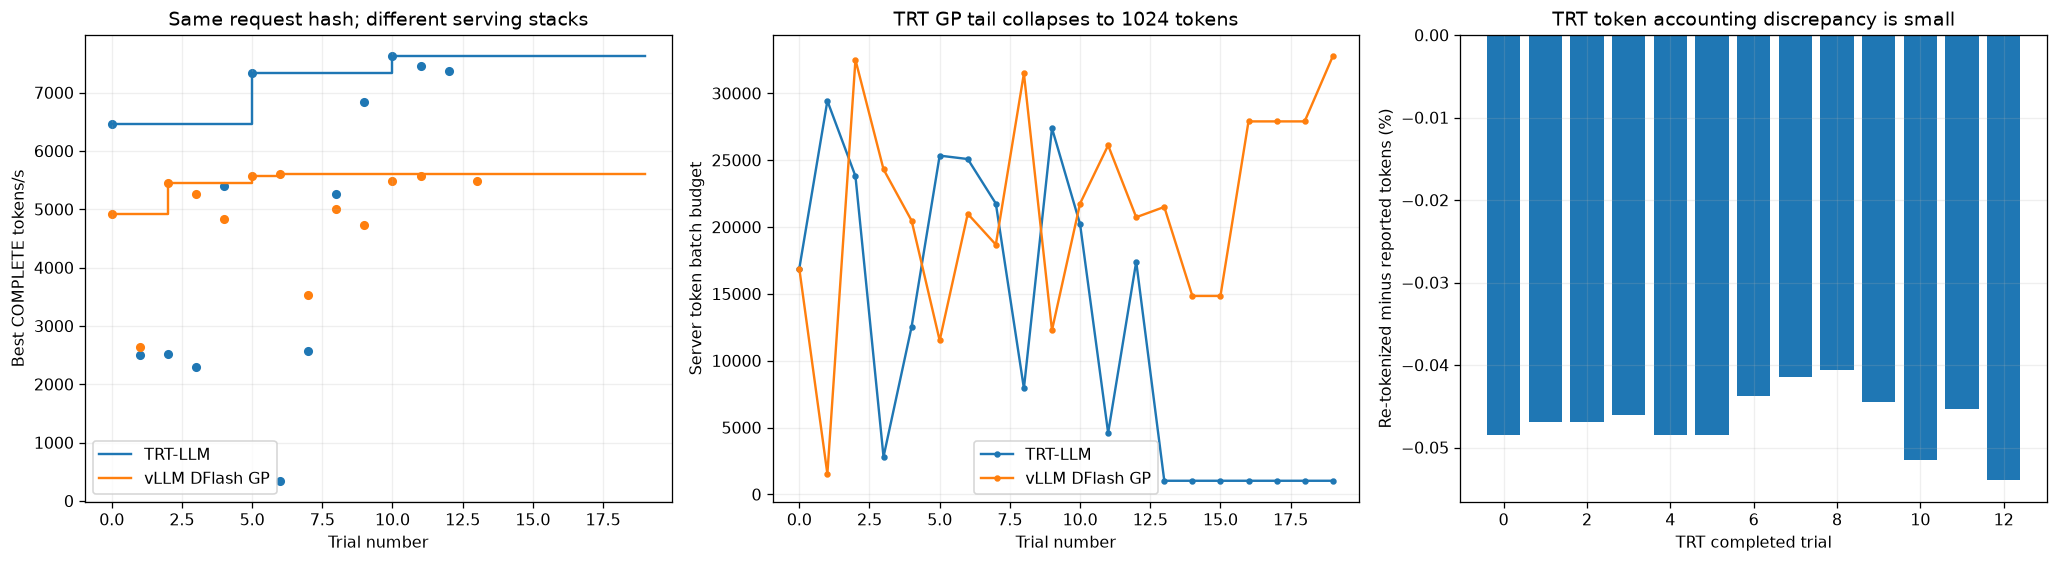

In [15]:
# Replay the TRT pruning rule independently; do not add these trials to the six-run data frame.
trt_study = optuna.create_study(direction="maximize", pruner=optuna.pruners.MedianPruner(**trt_cfg["pruner_settings"]))
trt_replay = []
for raw in trt_rows:
    intermediate = {int(k.rsplit(".", 1)[1]): float(v) for k, v in raw.items()
                    if k.startswith("trial/intermediate_values.") and v is not None}
    prefix = {}
    for step in sorted(intermediate):
        if step == trt_cfg["checkpoint_requests"][-1]: continue
        prefix[step] = intermediate[step]
        predicted = trt_study.pruner.prune(trt_study, optuna.trial.create_trial(state=TrialState.RUNNING, intermediate_values=prefix))
        actual = raw["trial/state"] == "PRUNED" and step == max(intermediate)
        trt_replay.append({"trial": raw["trial/number"], "step": step, "matches": predicted == actual})
    state = TrialState[raw["trial/state"]]
    options = {"state": state, "intermediate_values": intermediate}
    if state == TrialState.COMPLETE: options["value"] = raw["objective/output_throughput"]
    trt_study.add_trial(optuna.trial.create_trial(**options))
assert all(r["matches"] for r in trt_replay)
print("TRT pruning decisions replayed:", len(trt_replay), "; mismatches: 0")
assert all(r.get("requests/completed") == 250 and r.get("requests/failed") == 0 for r in trt_pruned)
display(pd.DataFrame([{"trial": r["trial/number"], "config_id": r["trial/config_id"],
                       "server_max_batch_size": r["parameters/max_batch_size"], "token_budget": r["parameters/max_num_tokens"],
                       "checkpoint_tok_s": r["trial/intermediate_values.250"], "completed": r["requests/completed"]} for r in trt_pruned]))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for label, rows in [("TRT-LLM", trt_rows), ("vLLM DFlash GP", sorted(dflash_gp_run["history"], key=lambda r: r["trial/number"]))]:
    numbers = [r["trial/number"] for r in rows]
    values = pd.Series([r.get("objective/output_throughput") if r["trial/state"] == "COMPLETE" else np.nan for r in rows])
    line = axes[0].step(numbers, values.cummax().ffill(), where="post", label=label)[0]
    axes[0].scatter(numbers, values, s=22, color=line.get_color())
    token_key = "parameters/max_num_tokens" if label == "TRT-LLM" else "parameters/max_num_batched_tokens"
    axes[1].plot(numbers, [r[token_key] for r in rows], marker=".", label=label)
axes[0].set(xlabel="Trial number", ylabel="Best COMPLETE tokens/s", title="Same request hash; different serving stacks")
axes[1].set(xlabel="Trial number", ylabel="Server token batch budget", title="TRT GP tail collapses to 1024 tokens")
axes[2].bar(trt_rich.trial, trt_rich.retokenized_difference_pct)
axes[2].set(xlabel="TRT completed trial", ylabel="Re-tokenized minus reported tokens (%)", title="TRT token accounting discrepancy is small")
for ax in axes[:2]: ax.legend()
fig.tight_layout()
plt.show()

## 15. What the 1024-request Nebius report establishes

The user reports 1024 benchmark requests/trial, at most 128 in flight, 30 fully executed trials, and about 8000 tokens/s. No run ID or result artifact is available here, so this result remains **reported, not independently verified**.

- 30×1024 = **30,720 benchmark requests**, plus warmup. This is work across trials, not 30,720 simultaneous requests. Trials that fail before benchmarking add none; failures during benchmarking can send a partial workload.
- If the job used the same 128 output tokens/request and `output_throughput`, 8000 tokens/s corresponds to **62.5 requests/s** and 131,072 output tokens over **16.384 s** per full trial. This is consistent in scale with TRT's 7623 tokens/s over 16.791 s.
- 8000 is only **4.94% above the verified TRT best**. A different configuration, runtime or finite-workload scheduling could account for such a gap; no specific cause is verified without the artifact.
- Increasing 1000 to 1024 total requests does not by itself increase the concurrency cap. It extends the workload and may alter the final drain; it is not an explanation for a general DFlash decline.
- Thirty executed trials offer more search opportunities than twenty. That affects best-of-search selection, not the throughput definition of any one fixed configuration. Verify whether 8000 denotes output-only or input-plus-output throughput before comparing.

,run,best_output_tok_s,status,requests
0,TRT-LLM GP (verified),"7,623.099",verified,1000
1,vLLM baseline GP (verified),"7,258.913",verified,896
2,vLLM DFlash GP (verified),"5,613.565",verified,1000
3,vLLM DFlash multivariate (verified),"5,710.270",verified,1000
4,Nebius job (user report),"8,000.000",unverified,1024


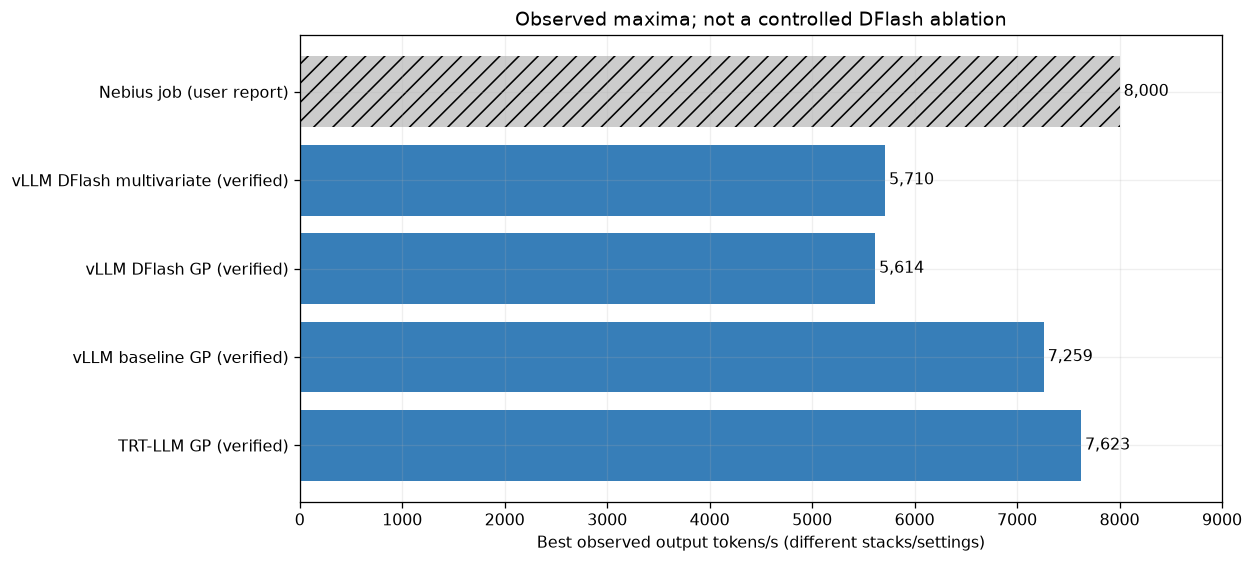

In [16]:
cross_stack = pd.DataFrame([
    {"run": "TRT-LLM GP (verified)", "best_output_tok_s": float(trt_best_result.output_throughput), "status": "verified", "requests": 1000},
    {"run": "vLLM baseline GP (verified)", "best_output_tok_s": float(base.objective.max()), "status": "verified", "requests": 896},
    {"run": "vLLM DFlash GP (verified)", "best_output_tok_s": float(df[(df.run_id == "zbyjlkdk") & (df.state == "COMPLETE")].objective.max()), "status": "verified", "requests": 1000},
    {"run": "vLLM DFlash multivariate (verified)", "best_output_tok_s": float(df[(df.run_id == "cvzosd1r") & (df.state == "COMPLETE")].objective.max()), "status": "verified", "requests": 1000},
    {"run": "Nebius job (user report)", "best_output_tok_s": 8000.0, "status": "unverified", "requests": 1024},
])
display(cross_stack)
fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.barh(cross_stack.run, cross_stack.best_output_tok_s, color=["#377eb8" if s == "verified" else "#cccccc" for s in cross_stack.status])
bars[-1].set_hatch("//")
for bar, value in zip(bars, cross_stack.best_output_tok_s):
    ax.text(value + 40, bar.get_y() + bar.get_height()/2, f"{value:,.0f}", va="center")
ax.set(xlabel="Best observed output tokens/s (different stacks/settings)", title="Observed maxima; not a controlled DFlash ablation", xlim=(0, 9000))
fig.tight_layout()
plt.show()

## 16. Updated assessment of the DFlash decline

**The measured TRT maximum appears credible within the available benchmark accounting.** There is no evidence that it reached 7.6k by using fewer requests, counting input tokens as output tokens, accepting failed requests, or promoting a pruned prefix to a full objective. Output correctness and exact target checkpoint identity are not established.

The most plausible *runtime hypothesis* for the lower DFlash ceiling is that the extra draft/verification work and fixed **15 speculative tokens** do not pay off for this target and workload under heavy batching. Low acceptance, excessive speculation depth, or implementation/kernel differences could each create that outcome, but no acceptance traces are available to choose among them. Speculation is not guaranteed to improve saturated throughput; [vLLM's documentation](https://docs.vllm.ai/en/latest/features/speculative_decoding/) discusses its latency benefits in medium-to-low-QPS, memory-bound workloads and notes that gains depend on the model, traffic and hardware.

Keep this separate from two established confounders: (1) the DFlash GP search repeatedly prunes proposals and fails to learn from them, but TRT shows that same loop, and (2) TRT-LLM and vLLM use different kernels/configurations and unverified matching target revisions. TRT's high value alone cannot measure the cost of the draft head.

**Best next experiment:** keep vLLM 0.31.0, pinned target and manifest, server settings and concurrency 128 fixed; run DFlash off/on with pruning disabled. After reproducing the gap, test a small supported range of speculative-token counts and record draft acceptance/accepted tokens per step, actual output totals and full latency summaries. Treat depth as its own speculative-decoding experiment setting rather than mixing it into unrelated cache/attention controls. This isolates runtime overhead; a separate comparison of GP with/without pruning isolates optimizer behavior.

## 17. Earlier Qwen3.5-9B DFlash versus baseline

- [DFlash / 3ct2p45q](https://forge.coreweave.com/wandb/maorblumberg-tel-aviv-university/speculative-decoding-benchmark/runs/3ct2p45q)
- [Baseline / sbj5cekm](https://forge.coreweave.com/wandb/maorblumberg-tel-aviv-university/speculative-decoding-benchmark/runs/sbj5cekm)

Both ran on the same recorded H100 host on September 9, 2026, using the same benchmark source commit. Both have **100 measured prompts, concurrency 1, five warmup requests, max output 128, temperature zero and non-streaming completions**. `c32` in names/tags does not reflect actual client concurrency.

The measured DFlash-labelled run reaches **257.58 vs 142.24 output tokens/s (1.811×)**; mean latency falls **44.81%**, and p95 falls **23.51%**. Every DFlash request is faster than the corresponding baseline request. The request tables contain 100/100 matching prompt previews in order, despite different prompt filenames. Full prompts/hashes are not saved, so exact full-input identity is not proved.

The source was retrieved from the recorded [benchmark commit](https://github.com/Maorb23/speculative_dflash_spark/blob/51ad928d75bbc8e3ed8727ef5ba084caef9a9891/scripts/bench_openai_server.py). The snapshot includes its text and both launcher scripts so these conclusions can be reviewed offline.

,mode,requests,concurrency,warmup_requests,output_tokens,wall_s,output_tok_s,mean_ms,p95_ms,wall_minus_sum_request_s,errors
0,dflash,100,1,5,12800,49.693,257.581,496.337,688.916,0.059,0
1,baseline,100,1,5,12800,89.990,142.239,899.285,900.618,0.061,0


Matching prompt previews: 100 /100
Matching completion previews: 23 /100
Server-version metadata: {'dflash': {'vllm': None, 'torch': None, 'wandb': '0.30.0', 'sglang': None, 'tensorrt_llm': None, 'transformers': '5.16.1'}, 'baseline': {'vllm': None, 'torch': None, 'wandb': '0.30.0', 'sglang': None, 'tensorrt_llm': None, 'transformers': '5.16.1'}}


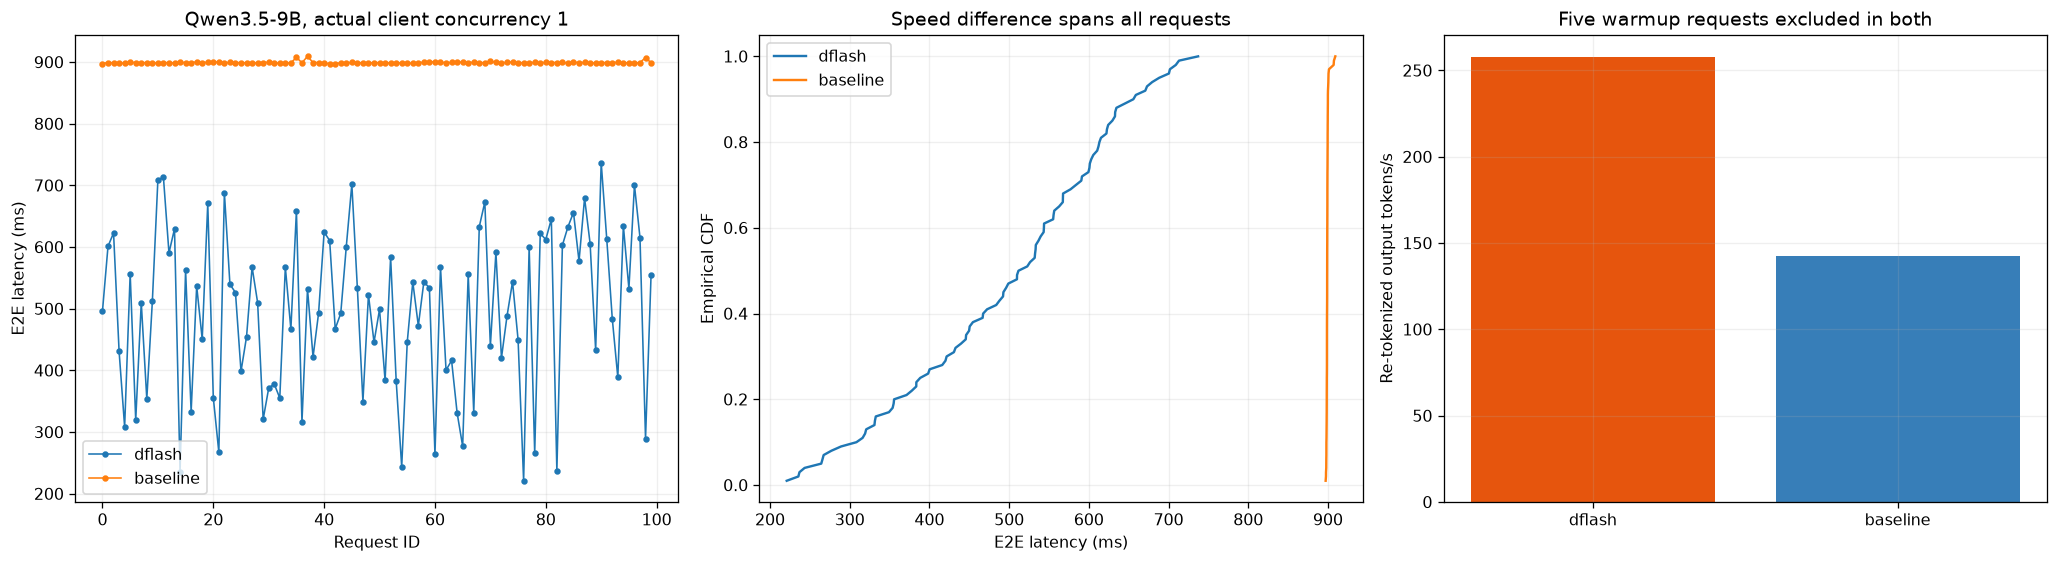

In [17]:
nine_b = snapshot["qwen35_9b_comparison"]
nine_runs = {r["config"]["mode"]: r for r in nine_b["runs"]}
nine_frames = {}
nine_summary_rows = []
for mode, run in nine_runs.items():
    result = run["benchmark_result"]
    requests = pd.DataFrame(result["requests"]).sort_values("id")
    summary_values = result["summary"]
    config = run["config"]
    assert len(requests) == config["num_prompts"] == 100
    assert requests.status.eq("ok").all() and requests.output_tokens.eq(128).all()
    assert not requests.warmup.any()
    assert config["concurrency"] == 1 and config["warmup"] == 5
    assert np.isclose(requests.output_tokens.sum() / summary_values["wall_time_s"], summary_values["output_tokens_per_second"])
    assert np.isclose(requests.latency_s.mean(), summary_values["mean_latency_s"])
    for pctl in [50, 90, 95, 99]:
        assert np.isclose(np.percentile(requests.latency_s, pctl), summary_values[f"p{pctl}_latency_s"])
    assert np.isclose(summary_values["output_tokens_per_second"], run["summary"]["summary/output_tokens_per_second"])
    nine_frames[mode] = requests
    nine_summary_rows.append({"mode": mode, "requests": len(requests), "concurrency": config["concurrency"],
                              "warmup_requests": config["warmup"], "output_tokens": requests.output_tokens.sum(),
                              "wall_s": summary_values["wall_time_s"], "output_tok_s": summary_values["output_tokens_per_second"],
                              "mean_ms": 1000 * requests.latency_s.mean(), "p95_ms": 1000 * np.percentile(requests.latency_s, 95),
                              "wall_minus_sum_request_s": summary_values["wall_time_s"] - requests.latency_s.sum(),
                              "errors": summary_values["error_count"]})
nine_summary = pd.DataFrame(nine_summary_rows)
display(nine_summary)
paired = nine_frames["baseline"].merge(nine_frames["dflash"], on="id", suffixes=("_baseline", "_dflash"), validate="one_to_one")
assert paired.prompt_preview_baseline.eq(paired.prompt_preview_dflash).all()
assert paired.latency_s_dflash.lt(paired.latency_s_baseline).all()
print("Matching prompt previews:", int(paired.prompt_preview_baseline.eq(paired.prompt_preview_dflash).sum()), "/100")
print("Matching completion previews:", int(paired.completion_preview_baseline.eq(paired.completion_preview_dflash).sum()), "/100")
print("Server-version metadata:", {mode: r["config"]["versions"] for mode, r in nine_runs.items()})

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for mode, requests in nine_frames.items():
    axes[0].plot(requests.id, requests.latency_s * 1000, marker=".", linewidth=1, label=mode)
    sorted_lat = np.sort(requests.latency_s.to_numpy()) * 1000
    axes[1].plot(sorted_lat, np.arange(1, 101)/100, label=mode)
axes[0].set(xlabel="Request ID", ylabel="E2E latency (ms)", title="Qwen3.5-9B, actual client concurrency 1")
axes[1].set(xlabel="E2E latency (ms)", ylabel="Empirical CDF", title="Speed difference spans all requests")
axes[2].bar(nine_summary["mode"], nine_summary.output_tok_s, color=["#e6550d", "#377eb8"])
axes[2].set(ylabel="Re-tokenized output tokens/s", title="Five warmup requests excluded in both")
for ax in axes[:2]: ax.legend()
fig.tight_layout()
plt.show()

### Timing and token-count audit

The benchmark source does the following:

1. Loads the tokenizer, creates the client and sends the **first five prompts once each as warmup**. These are five requests, not five full 100-prompt rounds.
2. Starts total wall timing **after** warmup, then sends 100 measured requests under a semaphore of one. The warmed prompts also occur in the timed workload; any persistent prefix caching can benefit these requests, but server caching settings were not captured.
3. Times each HTTP completion, then re-tokenizes the returned text to count output tokens. Global wall time includes re-tokenization and client scheduling, while individual request latency ends before that tokenization.
4. Computes throughput as returned re-tokenized token total divided by global wall time, and latency percentiles over successful requests. All 100 requests succeed in both runs and each records 128 output tokens.

The total wall durations exceed summed request latency by about **0.06 s in each run**, consistent with modest client/tokenization overhead. There is no discovered warmup inclusion, assumed-token-count or error-exclusion explanation for the measured 1.81× difference. Since both received five warmup requests, **warmup alone is not an explanation for their relative advantage**.

## 18. Reproducibility and attribution flaws

**Actual server configuration was not recorded or verified.** In this script, `--mode`, `--draft-model`, `--framework` and `--profile` label the experiment; they do not launch/reconfigure the existing server. Requests send the target model name, prompt, max tokens and temperature. Draft depth is read from the *client process environment* for metadata only. Here `num_speculative_tokens`, `dflash_block_size`, vLLM/torch versions and pinned revisions are missing. Thus the artifacts alone cannot prove the server used 15 speculative tokens, the intended runtime, or identical base settings.

**The launcher defaults differ at the recorded source commit.** If these `.sh` launchers were used without overrides:

| Setting | `launch_baseline.sh` | `launch_dflash.sh` |
|---|---|---|
| vLLM executable | explicit `.venv-vllm-dspark/bin/vllm` | `vllm` from PATH |
| H100 dtype | BF16 | BF16 |
| GPU memory utilization | explicit 0.90 | runtime default |
| Max sequences | explicit 32 | runtime default |
| Max batched tokens | omitted unless configured | explicit 32768 by default |
| TP | explicit 1 by default | omitted in vLLM branch |
| Speculation | none | DFlash, default 15 tokens |

These scripts reveal a **possible runtime/config confounder**, not proof of which launch command actually served these runs. Startup logs, executable/package versions and resolved engine configs are needed. The client config's `dtype=auto` also does not prove server dtype: the H100 launcher resolves auto to BF16 in its own shell.

**Output equivalence was not established.** Only 23/100 completion previews match; 77 differ at temperature zero. Different numerical/runtime paths can change greedy outputs, and previews are truncated, so this does not automatically establish a speculative-decoding bug. It does require full-output/target-revision checks before calling the comparison correctness-preserving. Draft acceptance, finish reasons, server usage counts and full outputs are not saved.

Other limitations: c32 labels are wrong; the baseline output filename mentions Qwen3-14B although the requested target is Qwen3.5-9B; prompt filenames differ and only previews are retained; no repeated/interleaved runs or server-load telemetry; TTFT is unavailable because streaming is disabled. The target name is sent on each request, making a filename mismatch a reporting issue rather than proof of the wrong target.

,source check
warmup precedes timed wall start,True
output counted from text,True
baseline launcher selects isolated executable,True
DFlash launcher uses PATH executable,True


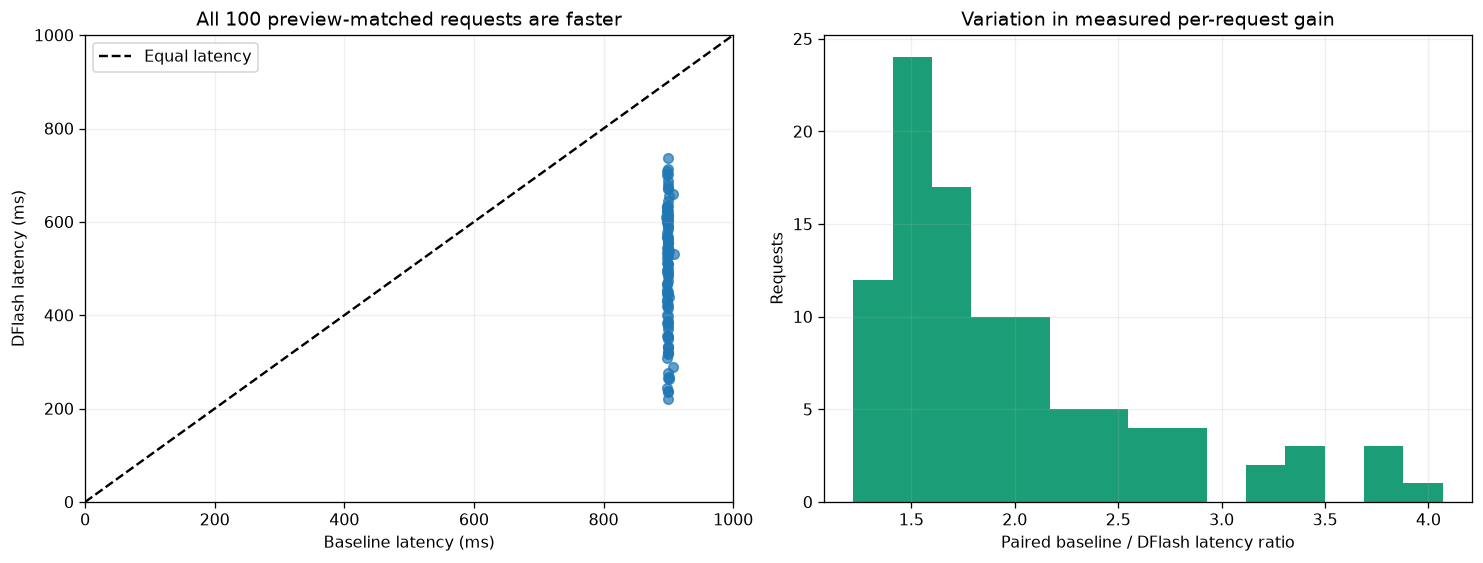

In [18]:
source = nine_b["recorded_source"]
checks_9b = {
    "warmup precedes timed wall start": source["bench_openai_server.py"].index("await run_warmup(client, tokenizer, prompts, args)") < source["bench_openai_server.py"].index("wall_start = time.perf_counter()"),
    "output counted from text": 'len(tokenizer.encode(completion, add_special_tokens=False))' in source["bench_openai_server.py"],
    "baseline launcher selects isolated executable": 'VLLM_BIN=${VLLM_BIN:-$REPO_ROOT/.venv-vllm-dspark/bin/vllm}' in source["launch_baseline.sh"],
    "DFlash launcher uses PATH executable": 'vllm serve "$TARGET_MODEL"' in source["launch_dflash.sh"],
}
assert all(checks_9b.values())
display(pd.Series(checks_9b, name="source check").to_frame())
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(paired.latency_s_baseline * 1000, paired.latency_s_dflash * 1000, alpha=0.7)
limits = [0, 1000]
axes[0].plot(limits, limits, "k--", label="Equal latency")
axes[0].set(xlabel="Baseline latency (ms)", ylabel="DFlash latency (ms)", title="All 100 preview-matched requests are faster", xlim=limits, ylim=limits)
axes[0].legend()
axes[1].hist(paired.latency_s_baseline / paired.latency_s_dflash, bins=15, color="#1b9e77")
axes[1].set(xlabel="Paired baseline / DFlash latency ratio", ylabel="Requests", title="Variation in measured per-request gain")
fig.tight_layout()
plt.show()

## 19. Why this gain does not contradict the Optuna studies

This is an **observed gain on a warm, long-running Qwen3.5-9B server at concurrency 1**, not a saturated-throughput comparison at concurrency 32 or 128. The notebook studies use Qwen3.5-4B, concurrency 128, a random-token workload with requested input length 512, streaming and independently restarted/sampled server configurations. The earlier benchmark uses natural-text previews and records `num_prefix_tokens=128`; its exact full prompt token lengths are not established from saved previews. These changes all affect the cost/benefit of speculation.

A larger target at low concurrency is a plausible setting for speculation to reduce sequential decode cost. At high offered load, drafting/verification can compete with batching efficiency; the fixed depth of 15 may or may not pay off. This is a hypothesis, not a mechanism established by these artifacts: no acceptance metrics or server trace exists to separate it from launcher/runtime differences.

**Assessment:** the measured latency/throughput improvement is internally consistent and broad across requests. No arithmetic flaw was found. The experiment has attribution and reproducibility gaps, so it supports “the DFlash-labelled setup was faster in this c1 test,” not “DFlash alone guarantees 1.81× at c128.”

For a controlled reproduction, use one explicit vLLM executable/build, identical pinned target/tokenizer revisions, identical captured native base settings and full prompt hashes; record actual server speculative config. Run off/on with the same five warmup requests at c1 first, repeat/interleave, then repeat at c128. Save full outputs, usage/finish reasons and draft acceptance. This determines whether the earlier gain reproduces and whether it persists under the notebook load.